<h1 style='font-weight:bold; color:#003366; text-align:center;'>Proyecto Final · Propuesta C</h1>
<h3 style='font-weight:bold; color:#003366; text-align:center;'>Rambla SA: perfiles de riesgo del inversor uruguayo y carteras modelo</h3>
<h4 style='font-weight:bold; color:#003366; text-align:center;'>Programación Analítica II · Docente Camila Palomeque · S2 2026</h4>

| | |
|---|---|
| **Pregunta del gerente** | ¿Cuántos clientes tienen una cartera que no se parece a lo que dijeron ser, y quiénes son? |
| **Datos** | `encuesta_inversores.csv`, `movimientos_cartera.csv`, `catalogo_instrumentos.csv`, `tasas_referencia.csv` (todo al 30/06/2026) |
| **Cómo correrlo** | *Kernel → Restart Kernel and Run All Cells* (o en Colab: *Entorno de ejecución → Ejecutar todas*) |

**Etapas:** 1. Análisis exploratorio y calidad · 2. Creación de variables · 3. Análisis de negocio · 4. Visualización · 5. Perfiles y carteras modelo

<h2 style='font-weight:bold; color:#003366;'>Preparación</h2>

In [1]:
# Si el notebook corre en Colab, monta el Drive. Si corre en una computadora, no hace nada.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("No estamos en Colab: los datos se leen de la carpeta datos/ del repositorio.")

No estamos en Colab: los datos se leen de la carpeta datos/ del repositorio.


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import seaborn as sns

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)


def ruta_datos(nombre_archivo):
    """Busca el archivo en las ubicaciones habituales del proyecto, incluida Colab."""
    candidatas = [
        Path("../datos") / nombre_archivo,
        Path("datos") / nombre_archivo,
        Path("/content/datos") / nombre_archivo,
        Path("/content/drive/MyDrive/Programación 2/datos") / nombre_archivo,
        Path("/content/drive/MyDrive/Programación 2") / nombre_archivo,
        Path(nombre_archivo),
    ]
    for candidata in candidatas:
        if candidata.exists():
            return str(candidata)
    raise FileNotFoundError(f"No se encontró {nombre_archivo}.")


# Todo lo que el notebook exporte va a la carpeta salidas/ del repositorio.
CARPETA_SALIDAS = Path("../salidas") if Path("../datos").exists() else Path("salidas")
CARPETA_SALIDAS.mkdir(exist_ok=True)

# Paleta: dos azules, un amarillo para destacar y un gris para el resto.
AZUL = "#003366"
AZUL_CLARO = "#6699CC"
AMARILLO = "#E7D25A"
GRIS = "#BBBBBB"
ROJO = "#BB3300"
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

pio.renderers.default = "colab" if Path("/content").exists() else "notebook_connected"
pio.templates.default = "plotly_white"

FECHA_CORTE = pd.Timestamp("2026-06-30")

print("pandas", pd.__version__)
print("Archivo de datos:", ruta_datos("encuesta_inversores.csv"))

pandas 2.2.3
Archivo de datos: ../datos/encuesta_inversores.csv


**Registro de decisiones.** La consigna pide que cada vez que se borre, impute o modifique algo se informe el porcentaje de la base afectado y se compare antes y después. Para no repetir el mismo código en cada paso, se escriben tres funciones cortas que imprimen ese reporte y lo anotan en una lista. Al final de la etapa la lista se muestra como tabla.

In [3]:
REGISTRO_DECISIONES = []


def reportar_borrado(filas_antes, filas_despues, tabla, decision):
    """Imprime y registra cuántas filas se borraron y qué porcentaje de la base son."""
    borradas = filas_antes - filas_despues
    porcentaje = borradas / filas_antes * 100
    REGISTRO_DECISIONES.append({"tabla": tabla, "decisión": decision, "filas afectadas": borradas,
                                "total de filas": filas_antes, "% afectado": round(porcentaje, 2)})
    print(f"{decision}: filas antes {filas_antes}, después {filas_despues}, "
          f"borradas {borradas} ({porcentaje:.2f}% de la base)")


def reportar_modificacion(cantidad, total, tabla, decision):
    """Imprime y registra cuántas celdas se modificaron y qué porcentaje de la base son."""
    porcentaje = cantidad / total * 100
    REGISTRO_DECISIONES.append({"tabla": tabla, "decisión": decision, "filas afectadas": cantidad,
                                "total de filas": total, "% afectado": round(porcentaje, 2)})
    print(f"{decision}: {cantidad} de {total} filas modificadas ({porcentaje:.2f}% de la base)")


def comparar_antes_despues(columna_antes, columna_despues):
    """Devuelve una tabla con las estadísticas principales de una columna antes y después del cambio."""
    comparacion = pd.DataFrame({"antes": columna_antes.describe(), "después": columna_despues.describe()})
    return comparacion.loc[["count", "mean", "50%", "std", "min", "max"]].T.round(2)

---
<h1 style='font-weight:bold; color:#003366;'>Etapa 1 · Análisis exploratorio y correcciones de calidad</h1>
<h3 style='font-weight:bold; color:#0033BB;'>1.1 Carga de los cuatro archivos declarando tipos y fechas</h3>

Criterio para declarar los tipos:
- **Identificadores** (`id_cliente`) como texto: son etiquetas, no cantidades, y así se unen bien las tablas.
- **Categóricas limpias** (sexo, nivel educativo, ocupación) como `category`.
- **Columnas sucias** (ingreso, perfil, departamento, etc.) como `str`: si se forzaran a número o categoría ahora, se perdería información antes de poder revisarla. Se convierten después de limpiarlas.
- **Fechas:** vienen mezcladas en dos formatos (`2026-06-24` y `12/06/2026`). `parse_dates` puede confundir día con mes (el 12/06 quedaría como 6 de diciembre), así que se leen como texto y se convierten indicando los dos formatos.

In [4]:
TIPOS_ENCUESTA = {
    "id_cliente": str, "fecha_respuesta": str, "sexo": "category", "departamento": str,
    "nivel_educativo": "category", "ocupacion": "category", "ingreso_mensual_liquido": str,
    "tiene_deudas": str, "tiene_fondo_emergencia": str, "perfil_autodeclarado": str,
    "tolerancia_perdida_maxima": str, "horizonte_inversion": str, "frecuencia_monitoreo": str,
    "retorno_esperado_anual": str, "reaccion_caida_20": str, "objetivo_principal": str,
    "fuente_informacion": str,
}
TIPOS_MOVIMIENTOS = {"id_cliente": str, "fecha_operacion": str, "tipo_operacion": "category",
                     "moneda": "category"}
TIPOS_CATALOGO = {"nombre_instrumento": str, "categoria": "category", "moneda": "category",
                  "liquidez": "category"}

encuesta_cruda = pd.read_csv(ruta_datos("encuesta_inversores.csv"), dtype=TIPOS_ENCUESTA)
movimientos_crudos = pd.read_csv(ruta_datos("movimientos_cartera.csv"), dtype=TIPOS_MOVIMIENTOS)
catalogo = pd.read_csv(ruta_datos("catalogo_instrumentos.csv"), dtype=TIPOS_CATALOGO)
tasas = pd.read_csv(ruta_datos("tasas_referencia.csv"), parse_dates=["fecha"])

In [5]:
def convertir_fechas(columna):
    """Convierte fechas escritas como AAAA-MM-DD o como DD/MM/AAAA."""
    fechas_iso = pd.to_datetime(columna, format="%Y-%m-%d", errors="coerce")
    fechas_latinas = pd.to_datetime(columna, format="%d/%m/%Y", errors="coerce")
    return fechas_iso.fillna(fechas_latinas)


print("Fechas con barra en la encuesta:", encuesta_cruda["fecha_respuesta"].str.contains("/").sum())
print("Fechas con barra en movimientos:", movimientos_crudos["fecha_operacion"].str.contains("/").sum())

encuesta_cruda["fecha_respuesta"] = convertir_fechas(encuesta_cruda["fecha_respuesta"])
movimientos_crudos["fecha_operacion"] = convertir_fechas(movimientos_crudos["fecha_operacion"])

# Verificación: ninguna fecha sin convertir y ninguna posterior al corte
for nombre, fechas in [("encuesta", encuesta_cruda["fecha_respuesta"]),
                       ("movimientos", movimientos_crudos["fecha_operacion"])]:
    print(f"{nombre}: sin convertir {fechas.isna().sum()} | rango {fechas.min().date()} a "
          f"{fechas.max().date()} | posteriores al 30/06/2026: {(fechas > FECHA_CORTE).sum()}")

Fechas con barra en la encuesta: 121
Fechas con barra en movimientos: 685
encuesta: sin convertir 0 | rango 2026-01-02 a 2026-06-30 | posteriores al 30/06/2026: 0
movimientos: sin convertir 0 | rango 2022-07-02 a 2026-05-31 | posteriores al 30/06/2026: 0


Todas las fechas se convirtieron y ninguna es posterior al 30/06/2026. Si se hubiera dejado que pandas interpretara por sí solo el formato, varias respuestas habrían quedado fechadas en diciembre de 2026, después del corte.

In [6]:
encuesta_cruda.head()

,id_cliente,fecha_respuesta,edad,sexo,departamento,cantidad_dependientes,nivel_educativo,ocupacion,ingreso_mensual_liquido,patrimonio_invertible_usd,tiene_deudas,tiene_fondo_emergencia,meses_gastos_cubiertos,anios_experiencia_invirtiendo,puntaje_test_conocimiento,conocimiento_autopercibido,perfil_autodeclarado,tolerancia_perdida_maxima,horizonte_inversion,frecuencia_monitoreo,retorno_esperado_anual,reaccion_caida_20,objetivo_principal,fuente_informacion,prioridad_plazo_fijo,prioridad_letras_bcu,prioridad_fondos_locales,prioridad_obligaciones,prioridad_etf_exterior,prioridad_inmuebles,prioridad_criptomonedas
0,20504,2026-06-24,52.0,Masculino,Montevideo,0,Terciaria completa,Profesional independiente,141700,4200.0,Sí,No,0.0,0.0,4.0,2.0,Conservador,Hasta 20%,3 a 5 años,Mensual,10% a 20%,Compraría más,Crecimiento del capital,Amigos y familia,7,6,4,5,1,3,2
1,20466,2026-03-29,62.0,Masculino,Colonia,0,Terciaria completa,Jubilado,$ 131.300,13900.0,Sí,No,0.0,0.0,4.0,1.0,Moderado,Hasta 10%,1 a 3 años,Trimestral,Menos de 5%,No haría nada,Generar una renta mensual,Investigación propia,7,6,4,5,2,3,1
2,20432,2026-01-11,40.0,Masculino,Maldonado,0,Terciaria completa,Jubilado,53700,4600.0,No,No,0.0,2.0,5.0,3.0,moderado,Hasta 5%,1 a 3 años,Trimestral,5% a 10%,No haría nada,Complemento jubilatorio,Asesor,7,6,4,3,2,5,1
3,20052,2026-02-21,48.0,Masculino,Canelones,0,Posgrado,Empresario / dueño de negocio,0,27700.0,Sí,SI,8.0,21.0,6.0,3.0,Conservador,Hasta 5%,Menos de 1 año,Anual o menos,Menos de 5%,No haría nada,Compra de vivienda,Asesor financiero,7,4,6,5,2,3,1
4,20084,2026-04-01,82.0,Femenino,Canelones,0,Posgrado,Jubilado,85100,12100.0,No,No,0.0,11.0,4.0,1.0,CONSERVADOR,No aceptaría ninguna pérdida,1 a 3 años,Anual o menos,5% a 10%,No haría nada,Complemento jubilatorio,Amigos y familia,7,6,3,4,1,5,2


In [7]:
movimientos_crudos.head()

,id_movimiento,id_cliente,id_instrumento,fecha_operacion,tipo_operacion,moneda,monto
0,700954,20141,4,2023-08-06,Compra,UI,17803.22
1,700912,20135,5,2023-11-28,Suscripción,UYU,46255.68
2,700236,20033,3,2025-02-26,Suscripción,UYU,39224.29
3,700992,20148,8,2023-12-09,Suscripción,UYU,195561.19
4,701697,20255,12,2024-05-17,Compra,USD,4324.05


In [8]:
catalogo

,id_instrumento,nombre_instrumento,categoria,moneda,inversion_minima,retorno_anual_historico,volatilidad_anual,nivel_riesgo,liquidez
0,1,Plazo fijo en pesos (BROU),Renta fija local,UYU,1000,0.085,0.005,1,Baja
1,2,Plazo fijo en dólares,Renta fija local,USD,500,0.033,0.004,1,Baja
2,3,Letras de Regulación Monetaria (BCU),Renta fija local,UYU,50000,0.092,0.013,1,Media
3,4,Notas del Tesoro en Unidades Indexadas,Renta fija local,UI,30000,0.031,0.026,2,Media
4,5,Fondo de inversión local (AFISA),Fondos,UYU,20000,0.071,0.041,2,Alta
5,6,Obligaciones negociables (BVM),Renta fija corporativa,USD,5000,0.065,0.058,3,Baja
6,7,Fideicomiso financiero,Renta fija corporativa,UI,40000,0.079,0.072,3,Muy baja
7,8,Ahorro voluntario en AFAP,Previsional,UYU,2000,0.049,0.061,3,Muy baja
8,9,ETF de índice global (S&P 500 / MSCI World),Renta variable,USD,1000,0.094,0.152,4,Alta
9,10,Acciones individuales del exterior,Renta variable,USD,500,0.101,0.243,5,Alta


In [9]:
tasas

,concepto,valor,unidad,fecha
0,"Inflación anual Uruguay (IPC, últimos 12 meses)",5.40,%,2026-06-30
1,Meta de inflación del BCU (centro del rango),4.50,%,2026-06-30
2,Tasa de política monetaria del BCU,8.75,%,2026-06-30
3,Tipo de cambio peso / dólar,42.80,UYU por USD,2026-06-30
4,Valor de la Unidad Indexada,6.55,UYU por UI,2026-06-30
5,Rendimiento de la Letra de Regulación Monetari...,9.20,%,2026-06-30
6,Inflación anual de Estados Unidos,2.70,%,2026-06-30
7,Rendimiento del bono del Tesoro de EE.UU. a 10...,4.10,%,2026-06-30


In [10]:
# ¿Las claves de unión entre tablas coinciden?
instrumentos_sin_catalogo = set(movimientos_crudos["id_instrumento"]) - set(catalogo["id_instrumento"])
print("Instrumentos de movimientos que no están en el catálogo:", len(instrumentos_sin_catalogo))

# ¿Cada operación está en la moneda de su instrumento?
control_moneda = pd.merge(movimientos_crudos, catalogo[["id_instrumento", "moneda"]],
                          on="id_instrumento", suffixes=("_operacion", "_catalogo"))
distinta_moneda = control_moneda["moneda_operacion"].astype(str) != control_moneda["moneda_catalogo"].astype(str)
print("Operaciones con moneda distinta a la del instrumento:", distinta_moneda.sum())

Instrumentos de movimientos que no están en el catálogo: 0
Operaciones con moneda distinta a la del instrumento: 0


La carga quedó bien: los instrumentos cruzan todos con el catálogo y cada operación está en la moneda de su instrumento (UYU, USD o UI). Esto confirma que los montos **no se pueden sumar sin convertirlos antes** (se hace en la Etapa 2).

<h3 style='font-weight:bold; color:#0033BB;'>1.2 Filas, columnas, tipos, categorías y descripción estadística</h3>

In [11]:
for nombre, tabla in [("encuesta", encuesta_cruda), ("movimientos", movimientos_crudos),
                      ("catálogo", catalogo), ("tasas", tasas)]:
    print(f"{nombre:<12} {tabla.shape[0]:>5} filas  {tabla.shape[1]:>3} columnas")
print()
print("Clientes distintos en la encuesta:", encuesta_cruda["id_cliente"].nunique())
print("Clientes distintos en movimientos:", movimientos_crudos["id_cliente"].nunique())

encuesta       657 filas   31 columnas
movimientos   4481 filas    7 columnas
catálogo        14 filas    9 columnas
tasas            8 filas    4 columnas

Clientes distintos en la encuesta: 640
Clientes distintos en movimientos: 706


In [12]:
encuesta_cruda.dtypes

id_cliente                               object
fecha_respuesta                  datetime64[ns]
edad                                    float64
sexo                                   category
departamento                             object
cantidad_dependientes                     int64
nivel_educativo                        category
ocupacion                              category
ingreso_mensual_liquido                  object
patrimonio_invertible_usd               float64
tiene_deudas                             object
tiene_fondo_emergencia                   object
meses_gastos_cubiertos                  float64
anios_experiencia_invirtiendo           float64
puntaje_test_conocimiento               float64
conocimiento_autopercibido              float64
perfil_autodeclarado                     object
tolerancia_perdida_maxima                object
horizonte_inversion                      object
frecuencia_monitoreo                     object
retorno_esperado_anual                  

In [13]:
# Cantidad de categorías de cada variable categórica
COLUMNAS_CATEGORICAS = [
    "sexo", "departamento", "nivel_educativo", "ocupacion", "tiene_deudas", "tiene_fondo_emergencia",
    "perfil_autodeclarado", "tolerancia_perdida_maxima", "horizonte_inversion", "frecuencia_monitoreo",
    "retorno_esperado_anual", "reaccion_caida_20", "objetivo_principal", "fuente_informacion",
]
encuesta_cruda[COLUMNAS_CATEGORICAS].nunique().sort_values(ascending=False)

departamento                 25
fuente_informacion            9
frecuencia_monitoreo          8
horizonte_inversion           7
perfil_autodeclarado          6
ocupacion                     6
objetivo_principal            6
tolerancia_perdida_maxima     5
retorno_esperado_anual        5
tiene_fondo_emergencia        4
nivel_educativo               4
reaccion_caida_20             4
tiene_deudas                  2
sexo                          2
dtype: int64

Varias columnas tienen **más categorías de las que deberían**. `perfil_autodeclarado` debería tener 3 y tiene 6, `departamento` debería tener 19 y tiene 25, y `tiene_fondo_emergencia` debería tener 2 y tiene 4. Es la misma respuesta escrita de distintas maneras:

In [14]:
for columna in ["perfil_autodeclarado", "tiene_fondo_emergencia", "horizonte_inversion",
                "frecuencia_monitoreo", "fuente_informacion"]:
    print(encuesta_cruda[columna].value_counts().to_string())
    print()

perfil_autodeclarado
Conservador    285
Moderado       157
Agresivo       127
CONSERVADOR     42
moderado        30
Agresivo        16

tiene_fondo_emergencia
No    317
Sí    271
NO     39
SI     30

horizonte_inversion
1 a 3 años        194
3 a 5 años        167
Más de 5 años     160
Menos de 1 año     59
Mas de 5 anios     29
1-3 años           29
3-5 años           19

frecuencia_monitoreo
Diaria           149
Trimestral       129
Anual o menos    117
Mensual          110
Semanal          108
Anual             20
DIARIA            16
mensual            8

fuente_informacion
Redes sociales               166
Amigos y familia             120
Banco o corredor de bolsa     96
Investigación propia          95
Prensa especializada          69
Asesor financiero             65
Redes Sociales                23
Asesor                        13
Banco                         10



In [15]:
COLUMNAS_CONTINUAS = ["edad", "patrimonio_invertible_usd", "meses_gastos_cubiertos",
                      "anios_experiencia_invirtiendo", "puntaje_test_conocimiento",
                      "conocimiento_autopercibido"]
encuesta_cruda[COLUMNAS_CONTINUAS].describe().round(2)

,edad,patrimonio_invertible_usd,meses_gastos_cubiertos,anios_experiencia_invirtiendo,puntaje_test_conocimiento,conocimiento_autopercibido
count,651.00,628.00,624.00,657.00,657.00,657.00
mean,46.64,24964.99,2.93,5.38,4.30,2.56
std,14.06,29705.02,3.93,4.70,2.06,1.00
min,0.00,-999.00,0.00,0.00,-1.00,1.00
25%,38.00,7400.00,0.00,2.00,3.00,2.00
50%,46.00,15900.00,0.00,4.00,4.00,3.00
75%,53.50,31650.00,6.00,7.00,6.00,3.00
max,154.00,279100.00,12.00,34.00,10.00,5.00


In [16]:
movimientos_crudos.groupby("moneda", observed=True)["monto"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
moneda,,,,,,,,
UI,831.0,19212.19,32289.48,-21478.63,4357.52,9375.69,19409.11,419665.76
USD,1664.0,3524.36,6453.51,-10651.22,639.19,1585.84,3548.29,92578.57
UYU,1934.0,108542.47,218319.16,-718329.50,19142.84,42716.68,115281.62,5317319.60


El `describe()` ya muestra problemas que vale la pena mirar dos veces:
- **Edad:** mínimo 0 y máximo 154, valores imposibles.
- **Patrimonio:** mínimo −999. No es un patrimonio negativo, es un código de "no contestó".
- **Puntaje del test:** mínimo −1, cuando la escala va de 0 a 10.
- **Montos:** hay mínimos negativos, aunque las operaciones son solo compras y suscripciones.
- `ingreso_mensual_liquido` no aparece porque es texto: mezcla formatos como `$ 131.300`, `22.000,00` y `Prefiero no contestar`.
- El monto mediano en pesos es unas 27 veces el de dólares. Es el efecto de la moneda, no que se invierta más.

<h3 style='font-weight:bold; color:#0033BB;'>1.3 Duplicados: formularios enviados dos veces vs. operaciones registradas dos veces</h3>

No son el mismo problema:
- **Formulario enviado dos veces:** el cliente mandó el mismo formulario dos veces. Las dos filas son idénticas. No cambia ningún dato, pero ese cliente pesaría doble en cualquier porcentaje.
- **Operación registrada dos veces:** la misma operación cargada dos veces en el sistema con **distinto `id_movimiento`**. Como el id cambia, `duplicated()` sobre la fila completa no la detecta. Es más grave porque **infla el patrimonio** del cliente.

In [17]:
print("Filas 100% duplicadas en la encuesta:", encuesta_cruda.duplicated().sum())
print("id_cliente repetidos en la encuesta: ", encuesta_cruda["id_cliente"].duplicated().sum())

# Ejemplo de un cliente que aparece dos veces
encuesta_cruda[encuesta_cruda["id_cliente"].duplicated(keep=False)].sort_values("id_cliente").head(4)

Filas 100% duplicadas en la encuesta: 17
id_cliente repetidos en la encuesta:  17


,id_cliente,fecha_respuesta,edad,sexo,departamento,cantidad_dependientes,nivel_educativo,ocupacion,ingreso_mensual_liquido,patrimonio_invertible_usd,tiene_deudas,tiene_fondo_emergencia,meses_gastos_cubiertos,anios_experiencia_invirtiendo,puntaje_test_conocimiento,conocimiento_autopercibido,perfil_autodeclarado,tolerancia_perdida_maxima,horizonte_inversion,frecuencia_monitoreo,retorno_esperado_anual,reaccion_caida_20,objetivo_principal,fuente_informacion,prioridad_plazo_fijo,prioridad_letras_bcu,prioridad_fondos_locales,prioridad_obligaciones,prioridad_etf_exterior,prioridad_inmuebles,prioridad_criptomonedas
12,20024,2026-02-07,53.0,Masculino,Maldonado,0,Terciaria incompleta,Empleado en relación de dependencia,"22.200,00",3500.0,No,Sí,8.0,8.0,5.0,4.0,Agresivo,Hasta 20%,Mas de 5 anios,Diaria,5% a 10%,Vendería una parte,Complemento jubilatorio,Redes sociales,7,6,5,4,2,3,1
447,20024,2026-02-07,53.0,Masculino,Maldonado,0,Terciaria incompleta,Empleado en relación de dependencia,"22.200,00",3500.0,No,Sí,8.0,8.0,5.0,4.0,Agresivo,Hasta 20%,Mas de 5 anios,Diaria,5% a 10%,Vendería una parte,Complemento jubilatorio,Redes sociales,7,6,5,4,2,3,1
59,20063,2026-02-01,51.0,Masculino,Río Negro,0,Terciaria completa,Empleado público,$ 90.100,5800.0,Sí,Sí,4.0,0.0,3.0,1.0,Conservador,Hasta 5%,3 a 5 años,Trimestral,10% a 20%,No haría nada,Crecimiento del capital,Redes sociales,4,6,7,2,3,5,1
239,20063,2026-02-01,51.0,Masculino,Río Negro,0,Terciaria completa,Empleado público,$ 90.100,5800.0,Sí,Sí,4.0,0.0,3.0,1.0,Conservador,Hasta 5%,3 a 5 años,Trimestral,10% a 20%,No haría nada,Crecimiento del capital,Redes sociales,4,6,7,2,3,5,1


**Decisión sobre formularios duplicados**
1. **Qué se encontró:** formularios enviados dos veces. Los 17 `id_cliente` repetidos son filas idénticas en todas las columnas, incluida la fecha.
2. **Cuántos:** 17 filas de 657 (2,59%).
3. **Decisión:** se borra la copia.
4. **Por qué:** es el mismo envío repetido. No hay que elegir entre dos versiones distintas de las respuestas, y si se dejaran, esos clientes pesarían doble.

In [18]:
# DECISIÓN: borrar los formularios duplicados.
encuesta = encuesta_cruda.drop_duplicates().reset_index(drop=True)
reportar_borrado(len(encuesta_cruda), len(encuesta), "encuesta", "Borrar formularios enviados dos veces")
print("¿Queda una fila por cliente?", encuesta["id_cliente"].is_unique)

Borrar formularios enviados dos veces: filas antes 657, después 640, borradas 17 (2.59% de la base)
¿Queda una fila por cliente? True


In [19]:
COLUMNAS_OPERACION = ["id_cliente", "id_instrumento", "fecha_operacion", "tipo_operacion", "moneda", "monto"]

print("id_movimiento repetidos:     ", movimientos_crudos["id_movimiento"].duplicated().sum())
print("Filas 100% duplicadas:       ", movimientos_crudos.duplicated().sum())

# Se ordena por id para que, entre dos copias, quede marcada como duplicada la cargada después.
movimientos_ordenados = movimientos_crudos.sort_values("id_movimiento")
es_operacion_repetida = movimientos_ordenados.duplicated(subset=COLUMNAS_OPERACION)
print("Iguales en todo menos el id:  ", es_operacion_repetida.sum())

movimientos_ordenados[movimientos_ordenados.duplicated(subset=COLUMNAS_OPERACION, keep=False)].sort_values(
    ["id_cliente", "fecha_operacion"]).head(6)

id_movimiento repetidos:      0
Filas 100% duplicadas:        0
Iguales en todo menos el id:   94


,id_movimiento,id_cliente,id_instrumento,fecha_operacion,tipo_operacion,moneda,monto
3241,700070,20007,12,2025-09-02,Compra,USD,1733.81
1193,704397,20007,12,2025-09-02,Compra,USD,1733.81
269,700109,20013,14,2025-09-27,Compra,USD,173.64
3494,704429,20013,14,2025-09-27,Compra,USD,173.64
2276,700151,20018,7,2023-06-02,Compra,UI,3114.44
4328,704424,20018,7,2023-06-02,Compra,UI,3114.44


Ningún `id_movimiento` se repite, pero **94 operaciones son iguales a otra** en cliente, instrumento, fecha, moneda y monto (con centavos incluidos), aunque tienen distinto id. Que coincidan hasta los centavos hace que sean dos cargas de la misma operación y no dos compras reales. Además, la copia suele tener un id alto (704xxx), como si se hubiera cargado después, en bloque.

**Una segunda forma de duplicación.** En movimientos hay 73 `id_cliente` que no están en la encuesta y que, a diferencia del resto (20001 a 20640), empiezan con 8. Se revisa si son operaciones reales o copias:

In [20]:
movimientos_sin_repetidas = movimientos_ordenados[~es_operacion_repetida]
es_id_con_8 = movimientos_sin_repetidas["id_cliente"].str.startswith("8")
operaciones_id_8 = movimientos_sin_repetidas[es_id_con_8]
operaciones_reales = movimientos_sin_repetidas[~es_id_con_8]
print("Operaciones con id_cliente que empieza con 8:", len(operaciones_id_8),
      "| clientes distintos:", operaciones_id_8["id_cliente"].nunique())

# ¿Coinciden instrumento, fecha, moneda y monto con una operación de un cliente real?
CLAVES_COPIA = ["id_instrumento", "fecha_operacion", "moneda", "monto"]
copias = pd.merge(operaciones_id_8, operaciones_reales, on=CLAVES_COPIA, suffixes=("_id8", "_real"))
print("Son copia exacta de una operación de un cliente real:", copias["id_movimiento_id8"].nunique())
copias[["id_cliente_id8", "id_cliente_real", "id_instrumento", "fecha_operacion", "moneda", "monto"]].head()

Operaciones con id_cliente que empieza con 8: 74 | clientes distintos: 73
Son copia exacta de una operación de un cliente real: 73


,id_cliente_id8,id_cliente_real,id_instrumento,fecha_operacion,moneda,monto
0,80469,20497,8,2025-01-15,UYU,668922.66
1,80397,20494,9,2026-02-06,USD,4884.97
2,80428,20524,1,2023-12-18,UYU,98721.07
3,80438,20073,4,2023-08-13,UI,4810.30
4,80440,20286,8,2022-07-16,UYU,26890.76


In [21]:
# La que no coincide: no tiene monto, pero coincide en instrumento, fecha y moneda con una operación real
no_coincide = operaciones_id_8[~operaciones_id_8["id_movimiento"].isin(copias["id_movimiento_id8"])]
print(no_coincide.to_string())
print()
print(pd.merge(operaciones_reales, no_coincide[["id_instrumento", "fecha_operacion", "moneda"]],
               on=["id_instrumento", "fecha_operacion", "moneda"]).to_string())

      id_movimiento id_cliente  id_instrumento fecha_operacion tipo_operacion moneda  monto
2792         704365      80355              12      2023-06-26         Compra    USD    NaN

   id_movimiento id_cliente  id_instrumento fecha_operacion tipo_operacion moneda   monto
0         703717      20556              12      2023-06-26         Compra    USD  793.65


**Decisión sobre operaciones duplicadas**
1. **Qué se encontró:** dos formas de duplicación. Por un lado, 94 operaciones cargadas dos veces para el mismo cliente con distinto id. Por otro, 74 operaciones a nombre de clientes con id 8xxxx: 73 son copias exactas de operaciones de clientes reales, y la restante es la misma copia pero sin el monto.
2. **Cuántos:** 94 de 4.481 filas (2,10%) y después 74 de 4.387 (1,69%).
3. **Decisión:** se borran las dos. De cada par repetido se conserva la operación con el id más bajo (la carga original).
4. **Por qué:** dejarlas contaría dos veces la misma plata, inflaría el patrimonio de esos clientes y el peso de esos instrumentos en su cartera. Las de id 8xxxx, además, no se pueden unir con ningún cliente de la encuesta.

In [22]:
# Primera decisión: borrar las operaciones cargadas dos veces conservando la de id más bajo.
movimientos = movimientos_ordenados[~es_operacion_repetida].copy()
reportar_borrado(len(movimientos_ordenados), len(movimientos), "movimientos",
                 "Borrar operaciones registradas dos veces")

# Segunda decisión: borrar las copias asignadas a clientes con id 8xxxx, que no existen.
filas_antes = len(movimientos)
movimientos = movimientos[~movimientos["id_cliente"].str.startswith("8")].copy()
reportar_borrado(filas_antes, len(movimientos), "movimientos", "Borrar copias a nombre de clientes 8xxxx")

Borrar operaciones registradas dos veces: filas antes 4481, después 4387, borradas 94 (2.10% de la base)
Borrar copias a nombre de clientes 8xxxx: filas antes 4387, después 4313, borradas 74 (1.69% de la base)


<h3 style='font-weight:bold; color:#0033BB;'>1.4 Faltantes por columna</h3>

In [23]:
nulos_cantidad = encuesta.isnull().sum()
nulos_porcentaje = (encuesta.isnull().sum() / len(encuesta) * 100).round(2)
nulos_encuesta = pd.DataFrame({"nulos": nulos_cantidad, "% nulos": nulos_porcentaje})
print("ENCUESTA")
print(nulos_encuesta[nulos_encuesta["nulos"] > 0].sort_values("nulos", ascending=False))
print()
print("MOVIMIENTOS")
print(movimientos.isnull().sum()[movimientos.isnull().sum() > 0])

ENCUESTA
                           nulos  % nulos
meses_gastos_cubiertos        31     4.84
patrimonio_invertible_usd     29     4.53
objetivo_principal            26     4.06
reaccion_caida_20             19     2.97
ingreso_mensual_liquido       13     2.03
edad                           6     0.94

MOVIMIENTOS
monto    51
dtype: int64


In [24]:
# Filas afectadas
encuesta[encuesta["patrimonio_invertible_usd"].isnull()][
    ["id_cliente", "edad", "ocupacion", "ingreso_mensual_liquido", "patrimonio_invertible_usd"]].head()

,id_cliente,edad,ocupacion,ingreso_mensual_liquido,patrimonio_invertible_usd
15,20550,58.0,Profesional independiente,0,NaN
76,20514,26.0,Empresario / dueño de negocio,$ 386.400,NaN
79,20373,38.0,Empleado en relación de dependencia,"69.300,00",NaN
81,20058,61.0,Profesional independiente,118500,NaN
83,20314,32.0,Empleado público,117900,NaN


In [25]:
encuesta[encuesta["meses_gastos_cubiertos"].isnull()][
    ["id_cliente", "tiene_fondo_emergencia", "meses_gastos_cubiertos"]].head()

,id_cliente,tiene_fondo_emergencia,meses_gastos_cubiertos
52,20185,No,NaN
78,20355,Sí,NaN
106,20093,No,NaN
133,20237,Sí,NaN
167,20134,No,NaN


In [26]:
movimientos[movimientos["monto"].isnull()].head()

,id_movimiento,id_cliente,id_instrumento,fecha_operacion,tipo_operacion,moneda,monto
2877,700122,20015,4,2024-04-23,Compra,UI,NaN
3762,700301,20042,14,2023-08-14,Suscripción,USD,NaN
3469,700307,20045,6,2026-03-13,Compra,USD,NaN
734,700360,20054,2,2026-05-06,Suscripción,USD,NaN
532,700597,20088,3,2026-01-05,Compra,UYU,NaN


Según `isnull()`, la encuesta tiene seis columnas con faltantes, y la más afectada es el patrimonio (4,5%). Pero `isnull()` solo ve las celdas **vacías**: en la sección siguiente aparecen distintas maneras de "no contestó" que esta tabla no está contando.

<h3 style='font-weight:bold; color:#0033BB;'>1.5 Valores raros, rangos imposibles y las formas de decir "no contestó"</h3>

**a) Categorías escritas de varias maneras.** Primero sacamos los espacios de los bordes con `.str.strip()`, y después cada variante la reemplazamos por la forma correcta con un diccionario escrito a mano, para que la corrección quede documentada.

In [27]:
CORRECCIONES_CATEGORIAS = {
    "perfil_autodeclarado": {"CONSERVADOR": "Conservador", "moderado": "Moderado"},
    "departamento": {"MONTEVIDEO": "Montevideo", "San Jose": "San José", "Rio Negro": "Río Negro",
                     "Tacuarembo": "Tacuarembó", "Paysandu": "Paysandú"},
    "tiene_fondo_emergencia": {"SI": "Sí", "NO": "No"},
    "horizonte_inversion": {"Mas de 5 anios": "Más de 5 años", "1-3 años": "1 a 3 años",
                            "3-5 años": "3 a 5 años"},
    # "Anual" y "Anual o menos" son la misma opción escrita distinto
    "frecuencia_monitoreo": {"DIARIA": "Diaria", "mensual": "Mensual", "Anual": "Anual o menos"},
    # "Asesor" y "Banco" son abreviaturas de las opciones completas
    "fuente_informacion": {"Redes Sociales": "Redes sociales", "Asesor": "Asesor financiero",
                           "Banco": "Banco o corredor de bolsa"},
}

for columna, correcciones in CORRECCIONES_CATEGORIAS.items():
    antes = encuesta[columna].copy()
    encuesta[columna] = encuesta[columna].str.strip().replace(correcciones)
    modificadas = (antes != encuesta[columna]).sum()
    print(f"{columna}: {antes.nunique()} categorías antes, {encuesta[columna].nunique()} después")
    reportar_modificacion(modificadas, len(encuesta), "encuesta", f"Unificar categorías de {columna}")
    print()

perfil_autodeclarado: 6 categorías antes, 3 después
Unificar categorías de perfil_autodeclarado: 87 de 640 filas modificadas (13.59% de la base)

departamento: 25 categorías antes, 19 después
Unificar categorías de departamento: 73 de 640 filas modificadas (11.41% de la base)

tiene_fondo_emergencia: 4 categorías antes, 2 después
Unificar categorías de tiene_fondo_emergencia: 67 de 640 filas modificadas (10.47% de la base)

horizonte_inversion: 7 categorías antes, 4 después
Unificar categorías de horizonte_inversion: 73 de 640 filas modificadas (11.41% de la base)

frecuencia_monitoreo: 8 categorías antes, 5 después
Unificar categorías de frecuencia_monitoreo: 43 de 640 filas modificadas (6.72% de la base)

fuente_informacion: 9 categorías antes, 6 después
Unificar categorías de fuente_informacion: 45 de 640 filas modificadas (7.03% de la base)



In [28]:
# Con las categorías ya limpias, se declaran como category
for columna in COLUMNAS_CATEGORICAS:
    encuesta[columna] = encuesta[columna].astype("category")

encuesta["perfil_autodeclarado"].value_counts()

perfil_autodeclarado
Conservador    315
Moderado       184
Agresivo       141
Name: count, dtype: int64

**b) Ingreso mensual con formatos mezclados.** La columna tiene el mismo número escrito de cuatro maneras (`22000`, `22000.00`, `22.000,00`, `$ 22.000`) y además textos de no respuesta. Se escribe una función que reconoce cada formato.

In [29]:
TEXTOS_NO_CONTESTA = ["Prefiero no contestar", "S/D"]


def convertir_ingreso(texto):
    """Convierte el ingreso escrito en cualquier formato a número (NaN si no contestó)."""
    if pd.isna(texto) or texto in TEXTOS_NO_CONTESTA:
        return np.nan
    texto = texto.replace("$", "").replace(" ", "")
    if "," in texto:                                  # 22.000,00 -> punto de miles y coma decimal
        texto = texto.replace(".", "").replace(",", ".")
    elif "." in texto and len(texto.split(".")[-1]) == 3:  # 22.000 -> el punto es de miles
        texto = texto.replace(".", "")
    return float(texto)                               # 22000 y 22000.00 ya son números


ingreso_texto = encuesta["ingreso_mensual_liquido"].copy()
print("Escritos con $:            ", ingreso_texto.str.contains("$", regex=False).sum())
print("Escritos con coma decimal: ", ingreso_texto.str.contains(",", regex=False).sum())
print("Textos de no respuesta:    ", ingreso_texto.isin(TEXTOS_NO_CONTESTA).sum())

encuesta["ingreso_mensual_liquido"] = ingreso_texto.apply(convertir_ingreso)
encuesta["ingreso_mensual_liquido"].describe().round(0)

Escritos con $:             94
Escritos con coma decimal:  155
Textos de no respuesta:     26


count       601.0
mean      85970.0
std       60694.0
min        -999.0
25%       46900.0
50%       71900.0
75%      110500.0
max      535900.0
Name: ingreso_mensual_liquido, dtype: float64

**c) Las formas de decir "no contestó".** `isnull()` solo detecta la celda vacía, pero la base tiene además:
1. **Textos:** `"Prefiero no contestar"` y `"S/D"` (sin datos) en el ingreso.
2. **El código `-999`** en ingreso y patrimonio, un valor típico de formularios para marcar "sin respuesta".
3. **El valor `0`** en ingreso y patrimonio. Ningún cliente de la firma tiene patrimonio invertible cero (la firma le conoce operaciones), y los que declaran ingreso 0 son empleados, empresarios y profesionales, no estudiantes.
4. **El código `-1`** en el puntaje del test, que va de 0 a 10.

In [30]:
patrimonio = encuesta["patrimonio_invertible_usd"]
ingreso = encuesta["ingreso_mensual_liquido"]
puntaje = encuesta["puntaje_test_conocimiento"]

formas_no_contesta = pd.DataFrame({
    "ingreso": [ingreso_texto.isnull().sum(), ingreso_texto.isin(TEXTOS_NO_CONTESTA).sum(),
                (ingreso == -999).sum(), (ingreso == 0).sum(), 0],
    "patrimonio": [patrimonio.isnull().sum(), 0, (patrimonio == -999).sum(), (patrimonio == 0).sum(), 0],
    "puntaje_test": [puntaje.isnull().sum(), 0, 0, 0, (puntaje == -1).sum()],
}, index=["celda vacía (lo único que ve isnull)", "texto de no respuesta", "código -999",
          "cero", "código -1"])
formas_no_contesta.loc["TOTAL no contestó"] = formas_no_contesta.sum()
formas_no_contesta

,ingreso,patrimonio,puntaje_test
celda vacía (lo único que ve isnull),13,29,0
texto de no respuesta,26,0,0
código -999,9,13,0
cero,14,9,0
código -1,0,0,18
TOTAL no contestó,62,51,18


In [31]:
encuesta.loc[ingreso == 0, "ocupacion"].value_counts()

ocupacion
Empresario / dueño de negocio          6
Empleado en relación de dependencia    3
Profesional independiente              3
Empleado público                       2
Estudiante                             0
Jubilado                               0
Name: count, dtype: int64

**Decisión sobre los códigos de no respuesta**
1. **Qué se encontró:** cuatro formas de "no contestó" además de la celda vacía.
2. **Cuántos:** con todas las formas, el patrimonio pasa de 29 faltantes (lo que veía `isnull()`) a 51, el ingreso de 13 a 62 y el test de 0 a 18.
3. **Decisión:** todos los códigos pasan a `NaN`. Antes se guarda una columna que marca quién no contestó, porque se usa en 1.7.
4. **Por qué:** si se dejaran −999 o 0 como números, bajarían los promedios y aparecerían clientes "sin patrimonio" que en realidad no contestaron.

In [32]:
# Marca de quién no contestó patrimonio o ingreso (se usa en 1.7)
encuesta["no_declara_patrimonio"] = patrimonio.isnull() | patrimonio.isin([-999, 0])
encuesta["no_declara_ingreso"] = ingreso.isnull() | ingreso.isin([-999, 0])

# DECISIÓN: los códigos de no respuesta pasan a NaN, porque no son valores reales.
CODIGOS_POR_COLUMNA = {
    "ingreso_mensual_liquido": [-999, 0],
    "patrimonio_invertible_usd": [-999, 0],
    "puntaje_test_conocimiento": [-1],
}
for columna, codigos in CODIGOS_POR_COLUMNA.items():
    antes = encuesta[columna].copy()
    es_codigo = antes.isin(codigos)
    encuesta.loc[es_codigo, columna] = np.nan
    reportar_modificacion(es_codigo.sum(), len(encuesta), "encuesta", f"Códigos {codigos} -> NaN en {columna}")
    print(comparar_antes_despues(antes, encuesta[columna]))
    print()

Códigos [-999, 0] -> NaN en ingreso_mensual_liquido: 23 de 640 filas modificadas (3.59% de la base)
         count      mean      50%       std      min       max
antes    601.0  85970.23  71900.0  60694.48   -999.0  535900.0
después  578.0  89406.75  75900.0  59342.45  22000.0  535900.0

Códigos [-999, 0] -> NaN en patrimonio_invertible_usd: 22 de 640 filas modificadas (3.44% de la base)
         count      mean      50%       std     min       max
antes    611.0  25189.38  16300.0  29980.23  -999.0  279100.0
después  589.0  26152.29  16800.0  30110.46  1500.0  279100.0

Códigos [-1] -> NaN en puntaje_test_conocimiento: 18 de 640 filas modificadas (2.81% de la base)
         count  mean  50%   std  min   max
antes    640.0  4.30  4.0  2.06 -1.0  10.0
después  622.0  4.46  5.0  1.87  0.0  10.0



Con los −999 y los ceros adentro, el mínimo y la media estaban distorsionados. Después del cambio, el patrimonio mínimo pasa de −999 a USD 1.500, y la media del test sube de 4,30 a 4,46.

**d) Rangos imposibles.**

In [33]:
EDAD_MINIMA = 18
EDAD_MAXIMA = 100

edad_imposible = (encuesta["edad"] < EDAD_MINIMA) | (encuesta["edad"] > EDAD_MAXIMA)
print("Edades fuera de 18 a 100:", edad_imposible.sum(), "| valores:", sorted(encuesta.loc[edad_imposible, "edad"].unique()))
encuesta.loc[edad_imposible, ["id_cliente", "edad", "ocupacion", "nivel_educativo", "anios_experiencia_invirtiendo"]].head(8)

Edades fuera de 18 a 100: 16 | valores: [np.float64(0.0), np.float64(16.0), np.float64(17.0), np.float64(154.0)]


,id_cliente,edad,ocupacion,nivel_educativo,anios_experiencia_invirtiendo
6,20254,0.0,Jubilado,Terciaria completa,8.0
45,20104,16.0,Empleado público,Terciaria incompleta,19.0
84,20255,0.0,Empleado en relación de dependencia,Posgrado,1.0
100,20062,154.0,Empleado en relación de dependencia,Secundaria completa,2.0
112,20109,0.0,Empleado en relación de dependencia,Terciaria incompleta,2.0
118,20079,0.0,Jubilado,Terciaria completa,8.0
125,20266,154.0,Empleado en relación de dependencia,Terciaria completa,17.0
240,20152,16.0,Jubilado,Terciaria incompleta,22.0


Las edades de 0 y 154 son errores evidentes. Las de 16 y 17 también: un menor no puede abrir una cuenta de inversión, y entre esos casos hay jubilados, empleados públicos, gente con posgrado y clientes con hasta 22 años de experiencia invirtiendo.

In [34]:
# DECISIÓN: las edades imposibles pasan a NaN y se imputan en 1.6 junto con las vacías.
edad_antes = encuesta["edad"].copy()
encuesta.loc[edad_imposible, "edad"] = np.nan
reportar_modificacion(edad_imposible.sum(), len(encuesta), "encuesta", "Edades fuera de 18 a 100 -> NaN")
comparar_antes_despues(edad_antes, encuesta["edad"])

Edades fuera de 18 a 100 -> NaN: 16 de 640 filas modificadas (2.50% de la base)


,count,mean,50%,std,min,max
antes,634.0,46.58,46.0,14.20,0.0,154.0
después,618.0,47.13,46.0,11.48,26.0,82.0


In [35]:
# El resto de los rangos no son defectuosos
print("Meses de gastos cubiertos fuera de 0 a 24:", (~encuesta["meses_gastos_cubiertos"].dropna().between(0, 24)).sum())
print("Experiencia negativa:                     ", (encuesta["anios_experiencia_invirtiendo"] < 0).sum())
print("Conocimiento autopercibido fuera de 1 a 5:", (~encuesta["conocimiento_autopercibido"].between(1, 5)).sum())
COLUMNAS_PRIORIDAD = [columna for columna in encuesta.columns if columna.startswith("prioridad_")]
prioridades_mal = encuesta[COLUMNAS_PRIORIDAD].apply(lambda fila: sorted(fila) != [1, 2, 3, 4, 5, 6, 7], axis=1)
print("Filas cuyas prioridades no son un orden de 1 a 7:", prioridades_mal.sum())

Meses de gastos cubiertos fuera de 0 a 24: 0
Experiencia negativa:                      0
Conocimiento autopercibido fuera de 1 a 5: 0
Filas cuyas prioridades no son un orden de 1 a 7: 0


**e) Montos de las operaciones.**

In [36]:
negativos = movimientos[movimientos["monto"] < 0]
print("Operaciones con monto negativo:", len(negativos))
print("Tipos de operación que tienen:", list(negativos["tipo_operacion"].unique()))

# ¿El monto sin el signo es normal para ese instrumento? Se compara con los percentiles 5 y 95 de los positivos.
positivos = movimientos[movimientos["monto"] > 0]
percentil_5 = positivos.groupby("id_instrumento")["monto"].quantile(0.05)
percentil_95 = positivos.groupby("id_instrumento")["monto"].quantile(0.95)
monto_sin_signo = negativos["monto"].abs()
dentro_del_rango = monto_sin_signo.between(negativos["id_instrumento"].map(percentil_5),
                                           negativos["id_instrumento"].map(percentil_95))
print(f"Negativos que, sin el signo, caen en el rango habitual de su instrumento: {dentro_del_rango.mean():.0%}")

Operaciones con monto negativo: 18
Tipos de operación que tienen: ['Compra', 'Suscripción']
Negativos que, sin el signo, caen en el rango habitual de su instrumento: 83%


**Decisión sobre montos negativos**
1. **Qué se encontró:** operaciones con monto negativo, aunque en la base solo hay compras y suscripciones (no hay ventas).
2. **Cuántos:** 18 de 4.313 (0,42%).
3. **Decisión:** se pasan a valor absoluto.
4. **Por qué:** una compra no puede tener monto negativo, así que el error está en el signo. En el 83% de los casos, el monto sin el signo cae en el rango habitual de su instrumento, lo que indica que el número está bien.

In [37]:
# DECISIÓN: montos negativos pasan a valor absoluto, seguramente error de signo.
cantidad_negativos = (movimientos["monto"] < 0).sum()
movimientos["monto"] = movimientos["monto"].abs()
reportar_modificacion(cantidad_negativos, len(movimientos), "movimientos", "Montos negativos -> valor absoluto")

Montos negativos -> valor absoluto: 18 de 4313 filas modificadas (0.42% de la base)


In [38]:
# Montos muy grandes: ¿errores o clientes grandes?
mediana_de_su_moneda = movimientos.groupby("moneda", observed=True)["monto"].transform("median")
montos_relativos = movimientos.assign(veces_la_mediana=movimientos["monto"] / mediana_de_su_moneda)
montos_grandes = pd.merge(montos_relativos.nlargest(5, "veces_la_mediana"),
                          encuesta[["id_cliente", "patrimonio_invertible_usd"]], on="id_cliente", how="left")
montos_grandes[["id_cliente", "id_instrumento", "moneda", "monto", "veces_la_mediana", "patrimonio_invertible_usd"]].round(1)

,id_cliente,id_instrumento,moneda,monto,veces_la_mediana,patrimonio_invertible_usd
0,20518,5,UYU,5317319.6,117.0,133000.0
1,20009,11,USD,92578.6,55.9,279100.0
2,20383,1,UYU,2310959.7,50.9,142000.0
3,20397,4,UI,419665.8,44.3,171900.0
4,20548,8,UYU,1854876.2,40.8,81500.0


Las operaciones más grandes (hasta 117 veces la mediana de su moneda) son de clientes que **declaran patrimonios altos**, entre USD 80.000 y 280.000. Son clientes grandes, no errores, así que **no se tocan**: borrarlas haría desaparecer justo a los clientes que más patrimonio aportan.

<h3 style='font-weight:bold; color:#0033BB;'>1.6 Errores de carga vs. preguntas que el encuestado salteó</h3>

No se tratan igual porque significan cosas distintas:

| Tipo | Qué es | Dónde aparece | Qué se hace |
|---|---|---|---|
| **Salteada porque no aplica** | El formulario saltea la pregunta | `meses_gastos_cubiertos` vacío en quien **no tiene** fondo de emergencia | El valor real se conoce: **0** |
| **Error de carga** | El dato existía pero se perdió | `meses_gastos_cubiertos` vacío en quien **sí tiene** fondo; edad vacía o imposible; monto vacío | Imputar si se puede estimar bien; si no, borrar |
| **Salteada a propósito** | El cliente eligió no contestar | Ingreso, patrimonio, test, reacción ante caída, objetivo | No se inventa una respuesta: se marca "Sin respuesta" o se estudia quién no contesta (1.7) |

In [39]:
meses_vacios_por_fondo = encuesta.groupby("tiene_fondo_emergencia", observed=True)["meses_gastos_cubiertos"].agg(
    vacios=lambda columna: columna.isnull().sum(), informados="count")
print(meses_vacios_por_fondo)
print()
sin_fondo = encuesta["tiene_fondo_emergencia"] == "No"
con_fondo = encuesta["tiene_fondo_emergencia"] == "Sí"
print("Sin fondo y con meses > 0:", (sin_fondo & (encuesta["meses_gastos_cubiertos"] > 0)).sum())
print("Con fondo y con meses = 0:", (con_fondo & (encuesta["meses_gastos_cubiertos"] == 0)).sum())

                        vacios  informados
tiene_fondo_emergencia                    
No                          17         332
Sí                          14         277

Sin fondo y con meses > 0: 0
Con fondo y con meses = 0: 0


La regla del formulario se cumple siempre: **todos** los que no tienen fondo y contestaron pusieron 0 meses, y nadie con fondo puso 0. Por lo tanto:
- Los 17 vacíos **sin fondo** son la pregunta salteada porque no aplicaba: el valor real es 0.
- Los 14 vacíos **con fondo** son errores de carga: se sabe que tienen fondo, pero se perdió cuántos meses cubre.

In [40]:
# Primera decisión: sin fondo y meses vacío -> 0 (no es una estimación, es el valor que corresponde).
meses_antes = encuesta["meses_gastos_cubiertos"].copy()
salteada = sin_fondo & meses_antes.isnull()
encuesta.loc[salteada, "meses_gastos_cubiertos"] = 0
reportar_modificacion(salteada.sum(), len(encuesta), "encuesta", "Meses vacíos sin fondo -> 0")

# Segunda decisión: con fondo y meses vacío -> mediana de quienes tienen fondo.
# La mediana se calcula solo entre los que tienen fondo; si se incluyera a los que tienen 0, se subestimaría.
mediana_meses_con_fondo = encuesta.loc[con_fondo, "meses_gastos_cubiertos"].median()
error_de_carga = con_fondo & encuesta["meses_gastos_cubiertos"].isnull()
encuesta.loc[error_de_carga, "meses_gastos_cubiertos"] = mediana_meses_con_fondo
print("Mediana de meses entre quienes tienen fondo:", mediana_meses_con_fondo)
reportar_modificacion(error_de_carga.sum(), len(encuesta), "encuesta", "Meses vacíos con fondo -> mediana")
comparar_antes_despues(meses_antes, encuesta["meses_gastos_cubiertos"])

Meses vacíos sin fondo -> 0: 17 de 640 filas modificadas (2.66% de la base)
Mediana de meses entre quienes tienen fondo: 6.0
Meses vacíos con fondo -> mediana: 14 de 640 filas modificadas (2.19% de la base)


,count,mean,50%,std,min,max
antes,609.0,2.88,0.0,3.89,0.0,12.0
después,640.0,2.88,0.0,3.85,0.0,12.0


In [41]:
# Tercera decisión: edad vacía o imposible -> mediana de edad de su ocupación.
# Es un dato obligatorio (error de carga) y la ocupación tiene relación con la edad.
edad_antes = encuesta["edad"].copy()
mediana_edad_ocupacion = encuesta.groupby("ocupacion", observed=True)["edad"].transform("median")
edad_vacia = encuesta["edad"].isnull()
encuesta["edad"] = encuesta["edad"].fillna(mediana_edad_ocupacion)
reportar_modificacion(edad_vacia.sum(), len(encuesta), "encuesta", "Edad vacía -> mediana de su ocupación")
comparar_antes_despues(edad_antes, encuesta["edad"])

Edad vacía -> mediana de su ocupación: 22 de 640 filas modificadas (3.44% de la base)


,count,mean,50%,std,min,max
antes,618.0,47.13,46.0,11.48,26.0,82.0
después,640.0,47.09,46.0,11.29,26.0,82.0


In [42]:
# Cuarta decisión: operaciones sin monto -> se borran.
# Sin el monto no se sabe cuánto pesa la operación en la cartera, e imputarlo inventaría patrimonio.
filas_antes = len(movimientos)
movimientos = movimientos.dropna(subset=["monto"])
reportar_borrado(filas_antes, len(movimientos), "movimientos", "Borrar operaciones sin monto")

Borrar operaciones sin monto: filas antes 4313, después 4262, borradas 51 (1.18% de la base)


In [43]:
# Las preguntas salteadas a propósito, ¿se concentran en algún perfil?
for columna in ["reaccion_caida_20", "objetivo_principal"]:
    print(f"% sin respuesta en {columna}:")
    print(encuesta.groupby("perfil_autodeclarado", observed=True)[columna]
          .apply(lambda columna_grupo: columna_grupo.isnull().mean() * 100).round(1).to_string())
    print()

% sin respuesta en reaccion_caida_20:
perfil_autodeclarado
Agresivo       2.8
Conservador    3.2
Moderado       2.7

% sin respuesta en objetivo_principal:
perfil_autodeclarado
Agresivo       2.1
Conservador    4.4
Moderado       4.9



In [44]:
# Quinta decisión: reacción ante caída y objetivo vacíos -> categoría "Sin respuesta".
# Los vacíos se reparten parejo entre perfiles (entre 2% y 5%). Imputar con la moda le asignaría
# al cliente una opinión que no dio.
for columna in ["reaccion_caida_20", "objetivo_principal"]:
    vacias = encuesta[columna].isnull().sum()
    encuesta[columna] = encuesta[columna].cat.add_categories("Sin respuesta").fillna("Sin respuesta")
    reportar_modificacion(vacias, len(encuesta), "encuesta", f"{columna} vacío -> 'Sin respuesta'")

# El test sin hacer (antes -1) queda como NaN: imputarlo inventaría conocimiento.
print("Test de conocimiento que queda sin dato:", encuesta["puntaje_test_conocimiento"].isnull().sum())

reaccion_caida_20 vacío -> 'Sin respuesta': 19 de 640 filas modificadas (2.97% de la base)
objetivo_principal vacío -> 'Sin respuesta': 26 de 640 filas modificadas (4.06% de la base)
Test de conocimiento que queda sin dato: 18


<h3 style='font-weight:bold; color:#0033BB;'>1.7 ¿Quién es el que no contesta? Faltantes de ingreso y patrimonio</h3>

La consigna advierte que los faltantes **no son aleatorios**. Para averiguar quién no contesta se usa una segunda fuente que no depende de lo que el cliente quiera decir: **el patrimonio que la firma le conoce por sus operaciones**.

Para sumar operaciones en distintas monedas hay que llevarlas a una sola. Se usa el **dólar**, porque el patrimonio declarado ya está en USD, con el tipo de cambio y el valor de la UI de `tasas_referencia` al 30/06/2026. En la Etapa 2 se explica más en detalle; acá se usa para el diagnóstico.

In [45]:
TIPO_CAMBIO = tasas.loc[tasas["concepto"] == "Tipo de cambio peso / dólar", "valor"].iloc[0]
VALOR_UI = tasas.loc[tasas["concepto"] == "Valor de la Unidad Indexada", "valor"].iloc[0]
DOLARES_POR_UNIDAD = {"USD": 1, "UYU": 1 / TIPO_CAMBIO, "UI": VALOR_UI / TIPO_CAMBIO}
print(f"Tipo de cambio: {TIPO_CAMBIO} pesos por dólar | 1 UI = {VALOR_UI} pesos = {VALOR_UI / TIPO_CAMBIO:.4f} dólares")

movimientos["monto_usd"] = movimientos["monto"] * movimientos["moneda"].astype(str).map(DOLARES_POR_UNIDAD)

patrimonio_conocido = movimientos.groupby("id_cliente")["monto_usd"].sum().rename("patrimonio_conocido_usd")
encuesta = pd.merge(encuesta, patrimonio_conocido, on="id_cliente", how="left")
print("Clientes de la encuesta sin ninguna operación en la firma:", encuesta["patrimonio_conocido_usd"].isnull().sum())

Tipo de cambio: 42.8 pesos por dólar | 1 UI = 6.55 pesos = 0.1530 dólares


Clientes de la encuesta sin ninguna operación en la firma: 7


In [46]:
# Entre los que sí declaran, ¿lo declarado se parece a lo que conoce la firma?
declaran = encuesta[~encuesta["no_declara_patrimonio"] & encuesta["patrimonio_conocido_usd"].notnull()]
cociente_declarado_conocido = declaran["patrimonio_invertible_usd"] / declaran["patrimonio_conocido_usd"]

print("Correlación declarado vs. conocido:",
      round(declaran["patrimonio_invertible_usd"].corr(declaran["patrimonio_conocido_usd"]), 3))
print("Declarado / conocido -> mínimo", round(cociente_declarado_conocido.min(), 2),
      "| mediana", round(cociente_declarado_conocido.median(), 2),
      "| máximo", round(cociente_declarado_conocido.max(), 1))

Correlación declarado vs. conocido: 0.974
Declarado / conocido -> mínimo 1.0 | mediana 1.43 | máximo 203.8


Entre los que contestan, lo declarado y lo que conoce la firma están **muy relacionados (correlación 0,97)**, y lo declarado **nunca es menor** a lo conocido. Tiene sentido: la firma ve solo la parte del patrimonio que el cliente invierte con ella. Por eso el patrimonio conocido es una buena referencia para averiguar quién no contesta.

In [47]:
comparacion_quien_contesta = encuesta.groupby("no_declara_patrimonio")["patrimonio_conocido_usd"].agg(
    clientes="count", media="mean", mediana="median").round(0)
comparacion_quien_contesta.index = ["Declara patrimonio", "No declara"]
comparacion_quien_contesta

,clientes,media,mediana
Declara patrimonio,582,19311.0,12234.0
No declara,51,31522.0,21509.0


In [48]:
# Porcentaje que no contesta según el quintil de patrimonio conocido
ETIQUETAS_QUINTIL = ["Q1 (menor)", "Q2", "Q3", "Q4", "Q5 (mayor)"]
encuesta["quintil_patrimonio_conocido"] = pd.qcut(encuesta["patrimonio_conocido_usd"], 5, labels=ETIQUETAS_QUINTIL)

no_contesta_por_quintil = (encuesta.groupby("quintil_patrimonio_conocido", observed=True)
                           [["no_declara_patrimonio", "no_declara_ingreso"]].mean() * 100).round(1)
no_contesta_por_quintil.columns = ["% no declara patrimonio", "% no declara ingreso"]
no_contesta_por_quintil

,% no declara patrimonio,% no declara ingreso
quintil_patrimonio_conocido,,
Q1 (menor),4.7,7.9
Q2,3.2,7.9
Q3,7.9,11.0
Q4,11.1,9.5
Q5 (mayor),13.4,12.6


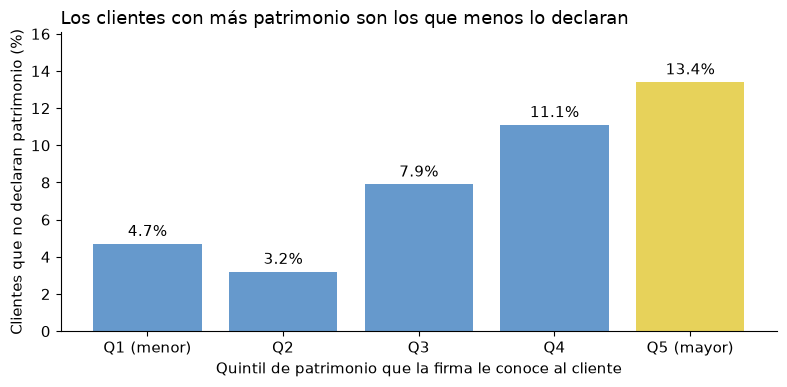

In [49]:
porcentajes = no_contesta_por_quintil["% no declara patrimonio"]
colores = [AMARILLO if quintil == "Q5 (mayor)" else AZUL_CLARO for quintil in porcentajes.index]

fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(porcentajes.index, porcentajes.values, color=colores)
ax.bar_label(barras, fmt="%.1f%%", padding=3)
ax.set_ylim(0, porcentajes.max() * 1.2)
ax.set_title("Los clientes con más patrimonio son los que menos lo declaran", loc="left")
ax.set_xlabel("Quintil de patrimonio que la firma le conoce al cliente")
ax.set_ylabel("Clientes que no declaran patrimonio (%)")
plt.tight_layout()
plt.savefig(CARPETA_SALIDAS / "1_7_no_respuesta_por_quintil.png", dpi=150)
plt.show()

**Conclusión: el que no contesta es el cliente de mayor patrimonio.** Los que no declaran tienen un patrimonio conocido mediano de unos USD 21.500, contra unos USD 12.200 de los que sí declaran. Además, la no respuesta pasa de alrededor del 4% en los dos quintiles más bajos al 13% en el más alto: casi el triple.

Es un faltante **no aleatorio**, y eso importa:
- **Si se borrara a estos clientes**, la base quedaría sesgada hacia los patrimonios chicos y se subestimaría el patrimonio que maneja la firma, justo en su segmento más importante.
- **Si se imputara con la mediana general**, a clientes ricos se les asignaría el patrimonio de un cliente promedio: el mismo sesgo, disimulado.

**Decisión sobre los clientes sin patrimonio declarado**
1. **Qué se encontró:** no declaran patrimonio sobre todo los clientes más ricos.
2. **Cuántos:** 51 de 640 (7,97%).
3. **Decisión:** se imputa con **patrimonio conocido × 1,43**, que es la mediana del cociente declarado/conocido entre los que sí contestan.
4. **Por qué:** se usa lo que la firma sabe de cada cliente en particular, respetando que el que no contesta tiene más patrimonio. Se usa la mediana del cociente porque hay valores extremos (hasta 200 veces) que inflarían un promedio.

In [50]:
# DECISIÓN: patrimonio no declarado -> patrimonio conocido x mediana del cociente declarado/conocido.
COCIENTE_MEDIANO = cociente_declarado_conocido.median()
patrimonio_antes = encuesta["patrimonio_invertible_usd"].copy()
sin_patrimonio = encuesta["patrimonio_invertible_usd"].isnull() & encuesta["patrimonio_conocido_usd"].notnull()
encuesta.loc[sin_patrimonio, "patrimonio_invertible_usd"] = (
    encuesta.loc[sin_patrimonio, "patrimonio_conocido_usd"] * COCIENTE_MEDIANO
)
print("Cociente mediano usado:", round(COCIENTE_MEDIANO, 3))
reportar_modificacion(sin_patrimonio.sum(), len(encuesta), "encuesta", "Patrimonio no declarado -> conocido x cociente")
print("Clientes que quedan sin patrimonio:", encuesta["patrimonio_invertible_usd"].isnull().sum())
comparar_antes_despues(patrimonio_antes, encuesta["patrimonio_invertible_usd"])

Cociente mediano usado: 1.43
Patrimonio no declarado -> conocido x cociente: 51 de 640 filas modificadas (7.97% de la base)
Clientes que quedan sin patrimonio: 0


,count,mean,50%,std,min,max
antes,589.0,26152.29,16800.0,30110.46,1500.00,279100.0
después,640.0,27660.86,17650.0,32080.25,825.47,279100.0


In [51]:
# ¿Qué habría pasado con cada alternativa?
alternativas = pd.DataFrame({
    "clientes": [patrimonio_antes.count(), len(encuesta), len(encuesta)],
    "mediana": [patrimonio_antes.median(), patrimonio_antes.fillna(patrimonio_antes.median()).median(),
                encuesta["patrimonio_invertible_usd"].median()],
    "patrimonio total (USD)": [patrimonio_antes.sum(), patrimonio_antes.fillna(patrimonio_antes.median()).sum(),
                               encuesta["patrimonio_invertible_usd"].sum()],
}, index=["Borrar a los que no contestan", "Imputar con la mediana general", "Imputar con lo conocido (elegida)"])
alternativas.round(0)

,clientes,mediana,patrimonio total (USD)
Borrar a los que no contestan,589,16800.0,15403700.0
Imputar con la mediana general,640,16800.0,16260500.0
Imputar con lo conocido (elegida),640,17650.0,17702953.0


Con la alternativa elegida, el patrimonio total de la base es de USD 17,7 millones. Borrando a los que no contestan quedaría en 15,4 millones, y con la mediana general en 16,3 millones. Las otras dos opciones subestiman lo que maneja la firma.

**Decisión sobre el ingreso no declarado**
1. **Qué se encontró:** el ingreso también falta más en los clientes con más patrimonio, aunque el patrón es más débil (del 8% en los quintiles bajos al 13% en el más alto).
2. **Cuántos:** 62 de 640 (9,69%).
3. **Decisión:** se imputa la **mediana de ingreso de los clientes de su mismo quintil de patrimonio conocido**.
4. **Por qué:** el ingreso no se puede deducir de las operaciones como el patrimonio, pero está asociado con él. Usar el quintil evita asignarle a un cliente rico el ingreso de uno chico.

In [52]:
# DECISIÓN: ingreso no declarado -> mediana de ingreso de su quintil de patrimonio conocido.
ingreso_antes = encuesta["ingreso_mensual_liquido"].copy()
mediana_ingreso_quintil = encuesta.groupby("quintil_patrimonio_conocido", observed=True)[
    "ingreso_mensual_liquido"].transform("median")
sin_ingreso = encuesta["ingreso_mensual_liquido"].isnull()
encuesta["ingreso_mensual_liquido"] = encuesta["ingreso_mensual_liquido"].fillna(mediana_ingreso_quintil)
reportar_modificacion(sin_ingreso.sum(), len(encuesta), "encuesta", "Ingreso no declarado -> mediana de su quintil")
comparar_antes_despues(ingreso_antes, encuesta["ingreso_mensual_liquido"])

Ingreso no declarado -> mediana de su quintil: 62 de 640 filas modificadas (9.69% de la base)


,count,mean,50%,std,min,max
antes,578.0,89406.75,75900.0,59342.45,22000.0,535900.0
después,640.0,88758.91,77900.0,56860.54,22000.0,535900.0


In [53]:
# Los 7 clientes que contestaron la encuesta pero no tienen ninguna operación quedan en la encuesta,
# pero no pueden entrar en el análisis "lo que dicen vs. lo que hacen" porque no tienen cartera.
encuesta["tiene_cartera"] = encuesta["patrimonio_conocido_usd"].notnull()
print("Clientes con cartera para analizar:", encuesta["tiene_cartera"].sum(), "de", len(encuesta))

Clientes con cartera para analizar: 633 de 640


<h3 style='font-weight:bold; color:#0033BB;'>Cierre de la Etapa 1</h3>

In [54]:
encuesta_sin_duplicados = encuesta_cruda.drop_duplicates()
COLUMNAS_CONTROL = ["edad", "ingreso_mensual_liquido", "patrimonio_invertible_usd", "meses_gastos_cubiertos",
                    "puntaje_test_conocimiento", "reaccion_caida_20", "objetivo_principal"]
faltantes_finales = pd.DataFrame({
    "isnull() en la base cruda": encuesta_sin_duplicados[COLUMNAS_CONTROL].isnull().sum(),
    "faltantes reales": [edad_vacia.sum(), formas_no_contesta.loc["TOTAL no contestó", "ingreso"],
                         formas_no_contesta.loc["TOTAL no contestó", "patrimonio"],
                         meses_vacios_por_fondo["vacios"].sum(),
                         formas_no_contesta.loc["TOTAL no contestó", "puntaje_test"],
                         encuesta_sin_duplicados["reaccion_caida_20"].isnull().sum(),
                         encuesta_sin_duplicados["objetivo_principal"].isnull().sum()],
    "faltantes después de limpiar": encuesta[COLUMNAS_CONTROL].isnull().sum(),
})
faltantes_finales

,isnull() en la base cruda,faltantes reales,faltantes después de limpiar
edad,6,22,0
ingreso_mensual_liquido,13,62,0
patrimonio_invertible_usd,29,51,0
meses_gastos_cubiertos,31,31,0
puntaje_test_conocimiento,0,18,18
reaccion_caida_20,19,19,0
objetivo_principal,26,26,0


In [55]:
registro = pd.DataFrame(REGISTRO_DECISIONES)
registro.to_csv(CARPETA_SALIDAS / "registro_decisiones.csv", index=False)
registro

,tabla,decisión,filas afectadas,total de filas,% afectado
0,encuesta,Borrar formularios enviados dos veces,17,657,2.59
1,movimientos,Borrar operaciones registradas dos veces,94,4481,2.10
2,movimientos,Borrar copias a nombre de clientes 8xxxx,74,4387,1.69
3,encuesta,Unificar categorías de perfil_autodeclarado,87,640,13.59
4,encuesta,Unificar categorías de departamento,73,640,11.41
5,encuesta,Unificar categorías de tiene_fondo_emergencia,67,640,10.47
6,encuesta,Unificar categorías de horizonte_inversion,73,640,11.41
7,encuesta,Unificar categorías de frecuencia_monitoreo,43,640,6.72
8,encuesta,Unificar categorías de fuente_informacion,45,640,7.03
9,encuesta,"Códigos [-999, 0] -> NaN en ingreso_mensual_li...",23,640,3.59


In [56]:
encuesta.to_csv(CARPETA_SALIDAS / "encuesta_limpia.csv", index=False)
movimientos.to_csv(CARPETA_SALIDAS / "movimientos_limpios.csv", index=False)
print("Encuesta limpia:", encuesta.shape, "| Movimientos limpios:", movimientos.shape)

Encuesta limpia: (640, 36) | Movimientos limpios: (4262, 8)


**Conclusiones de Etapa 1**
1. **Duplicados:** se borraron 17 formularios enviados dos veces, 94 operaciones cargadas dos veces con distinto id y 74 copias de operaciones reales a nombre de clientes inexistentes (ids 8xxxx).
2. **Categorías:** se unificaron mayúsculas, tildes, espacios y abreviaturas en 6 columnas (por ejemplo, el perfil pasó de 6 a 3 categorías).
3. **"No contestó":** además de la celda vacía había textos, el −999, el 0 y el −1. Contando todas las formas, los faltantes de patrimonio pasan de 29 a 51 y los de ingreso de 13 a 62.
4. **Valores imposibles:** edades de 0, 16, 17 y 154 años, y 18 montos negativos (error de signo).
5. **Errores de carga vs. salteos:** un vacío de meses de fondo en quien no tiene fondo es 0; en quien sí tiene, es un error de carga. Las preguntas salteadas a propósito no se inventan.
6. **Faltantes no aleatorios:** **el que no declara patrimonio es el cliente más rico.** Por eso no se lo borra ni se lo imputa con la mediana general, sino con el patrimonio que la firma le conoce.

---
<h1 style='font-weight:bold; color:#003366;'>Etapa 2 · Creación de variables</h1>

El encargo del gerente es comparar lo que los clientes **dicen** con lo que **hacen**. Lo que dicen está en la encuesta. Lo que hacen hay que construirlo a partir de los movimientos: cuánto tiene cada cliente, en qué instrumentos y qué tan riesgosa es esa cartera.

<h3 style='font-weight:bold; color:#0033BB;'>2.1 Normalizar las tres monedas a una sola</h3>

Se usa el **dólar** como moneda común por tres razones:
1. El patrimonio declarado en la encuesta ya está en dólares, así que se puede comparar directo.
2. La mayoría de los instrumentos del catálogo están en dólares.
3. En Uruguay el dólar es la moneda de referencia del ahorro.

Se usan el tipo de cambio y el valor de la UI **al 30/06/2026**, la fecha de corte, para valuar todas las carteras en el mismo momento. La conversión ya se aplicó en la 1.7 (columna `monto_usd`); acá se muestra y se verifica.

*Limitación:* se suman los montos invertidos (lo que el cliente puso), no el valor actual de mercado de cada inversión, que no está en los datos.

In [57]:
tabla_conversion = pd.DataFrame({
    "moneda": ["USD", "UYU", "UI"],
    "cómo se convierte": ["queda igual", f"se divide entre {TIPO_CAMBIO}", f"x {VALOR_UI} y se divide entre {TIPO_CAMBIO}"],
    "dólares por unidad": [DOLARES_POR_UNIDAD["USD"], DOLARES_POR_UNIDAD["UYU"], DOLARES_POR_UNIDAD["UI"]],
})
tabla_conversion.round(4)

,moneda,cómo se convierte,dólares por unidad
0,USD,queda igual,1.0000
1,UYU,se divide entre 42.8,0.0234
2,UI,x 6.55 y se divide entre 42.8,0.1530


In [58]:
# El ejemplo de la consigna: un plazo fijo de $ 400.000 contra un ETF de USD 10.000
ejemplo_consigna = pd.DataFrame({
    "inversión": ["Plazo fijo en pesos", "ETF global"],
    "monto original": [400_000, 10_000],
    "moneda": ["UYU", "USD"],
})
ejemplo_consigna["monto en USD"] = ejemplo_consigna["monto original"] * ejemplo_consigna["moneda"].map(DOLARES_POR_UNIDAD)
ejemplo_consigna.round(0)

,inversión,monto original,moneda,monto en USD
0,Plazo fijo en pesos,400000,UYU,9346.0
1,ETF global,10000,USD,10000.0


Sin convertir, el plazo fijo parece 40 veces más grande que el ETF. En dólares son casi iguales (USD 9.346 contra USD 10.000).

In [59]:
# Peso de cada moneda en el total invertido, antes y después de convertir
totales_por_moneda = movimientos.groupby("moneda", observed=True).agg(
    operaciones=("monto", "count"),
    suma_sin_convertir=("monto", "sum"),
    suma_en_usd=("monto_usd", "sum"),
)
totales_por_moneda["% sin convertir"] = totales_por_moneda["suma_sin_convertir"] / totales_por_moneda["suma_sin_convertir"].sum() * 100
totales_por_moneda["% en dólares"] = totales_por_moneda["suma_en_usd"] / totales_por_moneda["suma_en_usd"].sum() * 100
totales_por_moneda.round(1)

,operaciones,suma_sin_convertir,suma_en_usd,% sin convertir,% en dólares
moneda,,,,,
UI,796,14866402.8,2275115.4,6.5,17.7
USD,1605,5722325.4,5722325.4,2.5,44.5
UYU,1861,207542429.5,4849122.2,91.0,37.7


Sin convertir, los pesos parecen el **91%** de todo lo invertido. En dólares son el **38%**, y el dólar (45%) pasa a ser la moneda principal. Cualquier análisis hecho con los montos originales habría sobrerrepresentado a los instrumentos en pesos y habría dado vuelta las conclusiones.

<h3 style='font-weight:bold; color:#0033BB;'>2.2 Reconstruir la cartera efectiva de cada cliente</h3>

Para cada cliente se suma cuánto invirtió en cada instrumento (en dólares) y qué **peso** tiene ese instrumento en su cartera, es decir, qué parte del total de su plata está en ese instrumento. Por ejemplo, si un cliente tiene USD 10.000 en total y USD 4.000 en plazo fijo, el plazo fijo pesa 0,40 (40%) en su cartera.

In [60]:
# Nombres cortos para mejor visualización
NOMBRES_CORTOS = {
    1: "PF pesos", 2: "PF dólares", 3: "Letras BCU", 4: "Notas UI", 5: "Fondo local",
    6: "Oblig. negociables", 7: "Fideicomiso", 8: "AFAP voluntario", 9: "ETF global",
    10: "Acciones exterior", 11: "Inmueble", 12: "Oro", 13: "Cripto", 14: "Dólares en caja",
}
catalogo["nombre_corto"] = catalogo["id_instrumento"].map(NOMBRES_CORTOS)

# Paso 1: cuánto tiene cada cliente en cada instrumento (una fila por cliente e instrumento)
cartera = movimientos.groupby(["id_cliente", "id_instrumento"], as_index=False)["monto_usd"].sum()

# Paso 2: el total de cada cliente, repetido en cada fila, y el peso de cada instrumento
cartera["total_cliente_usd"] = cartera.groupby("id_cliente")["monto_usd"].transform("sum")
cartera["peso"] = cartera["monto_usd"] / cartera["total_cliente_usd"]

# Paso 3: agregamos datos del instrumento (riesgo, liquidez, categoría)
cartera = pd.merge(cartera, catalogo[["id_instrumento", "nombre_corto", "categoria", "nivel_riesgo", "liquidez"]],
                   on="id_instrumento", how="left")

print("Filas (cliente x instrumento):", len(cartera), "| clientes:", cartera["id_cliente"].nunique())
print("¿Los pesos de cada cliente suman 1?", np.allclose(cartera.groupby("id_cliente")["peso"].sum(), 1))
cartera.head(8).round(3)

Filas (cliente x instrumento): 1721 | clientes: 633
¿Los pesos de cada cliente suman 1? True


,id_cliente,id_instrumento,monto_usd,total_cliente_usd,peso,nombre_corto,categoria,nivel_riesgo,liquidez
0,20001,2,2036.220,34611.525,0.059,PF dólares,Renta fija local,1,Baja
1,20001,5,3323.797,34611.525,0.096,Fondo local,Fondos,2,Alta
2,20001,6,15476.920,34611.525,0.447,Oblig. negociables,Renta fija corporativa,3,Baja
3,20001,7,12204.638,34611.525,0.353,Fideicomiso,Renta fija corporativa,3,Muy baja
4,20001,8,1569.950,34611.525,0.045,AFAP voluntario,Previsional,3,Muy baja
5,20002,6,5870.210,14852.828,0.395,Oblig. negociables,Renta fija corporativa,3,Baja
6,20002,8,7603.288,14852.828,0.512,AFAP voluntario,Previsional,3,Muy baja
7,20002,9,1379.330,14852.828,0.093,ETF global,Renta variable,4,Alta


In [61]:
# Ejemplo: cartera del cliente
cartera[cartera["id_cliente"] == "20004"][["nombre_corto", "monto_usd", "peso", "nivel_riesgo", "liquidez"]].round(2)

,nombre_corto,monto_usd,peso,nivel_riesgo,liquidez
11,PF pesos,4549.47,0.41,1,Baja
12,ETF global,2563.12,0.23,4,Alta
13,Acciones exterior,914.16,0.08,5,Alta
14,Oro,3156.51,0.28,4,Media


<h3 style='font-weight:bold; color:#0033BB;'>2.3 Medida del riesgo efectivo de la cartera</h3>

Para cada cliente, el riesgo efectivo es el **promedio del nivel de riesgo de sus instrumentos, ponderado por el peso de cada uno en la cartera**:

$$\text{riesgo efectivo} = \sum_{\text{instrumentos}} \text{peso} \times \text{nivel de riesgo}$$

El resultado queda en la misma escala de la firma, de 1 (más conservador) a 5 (más agresivo).

**Por qué se pondera por monto invertido y no por cantidad de instrumentos:** el riesgo que corre un cliente depende de **cuánta plata** tiene expuesta, no de cuántos productos distintos compró. Un cliente con USD 50.000 en plazo fijo (riesgo 1) y USD 100 en cripto (riesgo 5) es conservador. Si se contara cada instrumento igual, el promedio de 1 y 5 daría 3 y lo mostraría como moderado, aunque el 99,8% de su plata esté en plazo fijo.

In [62]:
cartera["riesgo_ponderado"] = cartera["peso"] * cartera["nivel_riesgo"]

# Variables de la cartera de cada cliente
variables_cartera = cartera.groupby("id_cliente").agg(
    riesgo_efectivo=("riesgo_ponderado", "sum"),
    riesgo_sin_ponderar=("nivel_riesgo", "mean"),
    cartera_total_usd=("monto_usd", "sum"),
    cantidad_instrumentos=("id_instrumento", "count"),
)
variables_cartera.describe().round(2)

,riesgo_efectivo,riesgo_sin_ponderar,cartera_total_usd,cantidad_instrumentos
count,633.00,633.00,633.00,633.00
mean,2.39,2.37,20294.73,2.72
std,1.04,0.98,25568.54,1.24
min,1.00,1.00,164.95,1.00
25%,1.55,1.67,5796.97,2.00
50%,2.25,2.25,12749.45,3.00
75%,3.00,3.00,24944.60,3.00
max,5.00,5.00,260735.33,8.00


In [63]:
# ¿Qué ocurre si no se pondera por los montos?
print("Correlación entre ponderar por monto y no ponderar:",
      round(variables_cartera["riesgo_efectivo"].corr(variables_cartera["riesgo_sin_ponderar"]), 2))

diferencia = (variables_cartera["riesgo_efectivo"] - variables_cartera["riesgo_sin_ponderar"]).abs()
print("Clientes cuyo riesgo cambia más de 1 punto:", (diferencia > 1).sum())

# El caso con más diferencia
cliente_ejemplo = diferencia.idxmax()
print(f"\nCliente {cliente_ejemplo}: riesgo ponderado por monto {variables_cartera.loc[cliente_ejemplo, 'riesgo_efectivo']:.2f}"
      f" | sin ponderar {variables_cartera.loc[cliente_ejemplo, 'riesgo_sin_ponderar']:.2f}")
cartera[cartera["id_cliente"] == cliente_ejemplo][["nombre_corto", "monto_usd", "peso", "nivel_riesgo"]].round(2)

Correlación entre ponderar por monto y no ponderar: 0.94
Clientes cuyo riesgo cambia más de 1 punto: 12

Cliente 20302: riesgo ponderado por monto 4.73 | sin ponderar 2.67


,nombre_corto,monto_usd,peso,nivel_riesgo
803,Fondo local,1627.17,0.05,2
804,Acciones exterior,31668.63,0.92,5
805,Dólares en caja,1130.58,0.03,1


En la mayoría de los clientes las dos medidas se parecen (correlación 0,94), pero cuando difieren, la ponderada por monto es la que tiene sentido. El cliente del ejemplo tiene el **92% de su plata en acciones del exterior** (riesgo 5). Por monto su riesgo da 4,73 (agresivo), mientras que sin ponderar daría 2,67, porque cuenta igual a los USD 1.100 que tiene en caja.

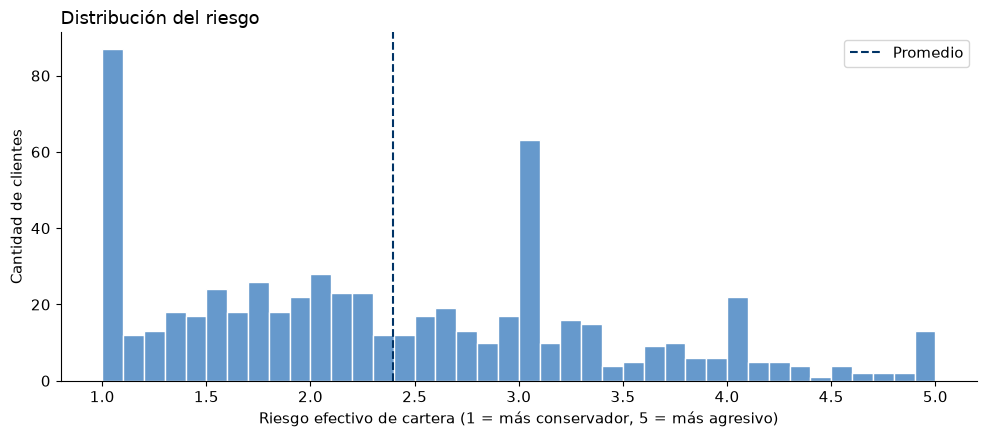

In [64]:
fig, ax = plt.subplots()
ax.hist(variables_cartera["riesgo_efectivo"], bins=40, color=AZUL_CLARO, edgecolor="white")
ax.axvline(variables_cartera["riesgo_efectivo"].mean(), color=AZUL, linestyle="--", label="Promedio")
ax.set_title("Distribución del riesgo", loc="left")
ax.set_xlabel("Riesgo efectivo de cartera (1 = más conservador, 5 = más agresivo)")
ax.set_ylabel("Cantidad de clientes")
ax.legend()
plt.tight_layout()
plt.savefig(CARPETA_SALIDAS / "2_3_riesgo_efectivo.png", dpi=150)
plt.show()

El riesgo efectivo promedio es 2,39 y la mediana 2,25: la mayoría de las carteras está en la zona baja de la escala. Hay un grupo grande en 1 (carteras solo en instrumentos de riesgo mínimo) y una cola más chica hacia 5.

<h3 style='font-weight:bold; color:#0033BB;'>2.4 De la medida continua a las tres categorías de la firma</h3>

**Cortes elegidos:**
- **Conservador:** riesgo efectivo menor a 2,5
- **Moderado:** de 2,5 a menos de 3,5
- **Agresivo:** 3,5 o más

**Justificación:** los instrumentos del catálogo se agrupan en tres familias: niveles 1-2 (plazo fijo, letras, notas en UI, fondos locales), nivel 3 (obligaciones, fideicomisos, AFAP, inmuebles) y niveles 4-5 (ETF, oro, acciones, cripto). Con estos cortes, una cartera se clasifica según **a qué nivel de instrumento se parece en promedio**, redondeando al entero más cercano. Si su riesgo redondea a 1 o 2 es conservadora, si redondea a 3 es moderada, y si redondea a 4 o 5 es agresiva.

In [65]:
CORTE_CONSERVADOR = 2.5
CORTE_AGRESIVO = 3.5
PERFILES = ["Conservador", "Moderado", "Agresivo"]

# Tabla de clientes con cartera: lo que dicen (encuesta) + lo que hacen (cartera)
clientes = pd.merge(encuesta[encuesta["tiene_cartera"]], variables_cartera, on="id_cliente", how="left")

clientes["perfil_real"] = pd.cut(
    clientes["riesgo_efectivo"],
    bins=[0, CORTE_CONSERVADOR, CORTE_AGRESIVO, 6],
    labels=PERFILES,
    right=False,   # cada tramo incluye su límite inferior: 2,5 ya es moderado y 3,5 ya es agresivo
)

perfil_real_resumen = clientes["perfil_real"].value_counts().reindex(PERFILES).to_frame("clientes")
perfil_real_resumen["%"] = (perfil_real_resumen["clientes"] / len(clientes) * 100).round(1)
perfil_real_resumen

,clientes,%
perfil_real,,
Conservador,353,55.8
Moderado,184,29.1
Agresivo,96,15.2


Según su cartera real, el 56% de los clientes es conservador, el 29% moderado y el 15% agresivo.

**¿Qué pasa si se mueven los cortes?** Se prueban otros cortes y se mide cómo cambian dos cosas: cuántos clientes caen en cada categoría y qué porcentaje de clientes tiene una cartera distinta de lo que declaró (el resultado central de la Etapa 3).

In [66]:
CORTES_A_PROBAR = [(2.0, 3.0), (2.0, 3.5), (2.25, 3.25), (2.5, 3.5), (2.5, 4.0), (2.75, 3.75), (2.75, 4.0)]

resultados_cortes = []
for corte_conservador, corte_agresivo in CORTES_A_PROBAR:
    perfil_con_estos_cortes = pd.cut(clientes["riesgo_efectivo"], bins=[0, corte_conservador, corte_agresivo, 6],
                                     labels=PERFILES, right=False)
    no_coincide = perfil_con_estos_cortes.astype(str) != clientes["perfil_autodeclarado"].astype(str)
    resultados_cortes.append({
        "cortes": f"{corte_conservador} / {corte_agresivo}",
        "% conservador": (perfil_con_estos_cortes == "Conservador").mean() * 100,
        "% moderado": (perfil_con_estos_cortes == "Moderado").mean() * 100,
        "% agresivo": (perfil_con_estos_cortes == "Agresivo").mean() * 100,
        "% que no coincide con lo declarado": no_coincide.mean() * 100,
    })

sensibilidad_cortes = pd.DataFrame(resultados_cortes).set_index("cortes").round(1)
sensibilidad_cortes

,% conservador,% moderado,% agresivo,% que no coincide con lo declarado
cortes,,,,
2.0 / 3.0,40.3,27.5,32.2,54.8
2.0 / 3.5,40.3,44.5,15.2,54.3
2.25 / 3.25,49.8,31.0,19.3,51.8
2.5 / 3.5,55.8,29.1,15.2,49.4
2.5 / 4.0,55.8,34.8,9.5,49.1
2.75 / 3.75,62.4,25.3,12.3,48.7
2.75 / 4.0,62.4,28.1,9.5,47.9


**Qué pasa al mover los cortes:** cambia **cuántos** clientes caen en cada categoría. Por ejemplo, bajar el primer corte de 2,5 a 2,0 pasa clientes de conservador a moderado, y el porcentaje de conservadores baja de 56% a 40%. Pero **el porcentaje de clientes cuya cartera no coincide con lo que declararon se mantiene cerca de la mitad en todos los casos** (entre 48% y 55%). La conclusión principal del trabajo no depende de los cortes elegidos.

**Conclusiones de Etapa 2**
1. **Moneda común:** todo se pasó a dólares al 30/06/2026. Sin convertir, los pesos parecían el 91% de lo invertido; en dólares son el 38%.
2. **Cartera efectiva:** se reconstruyó la cartera de 633 clientes: cuánto tienen, en qué instrumentos y qué peso tiene cada uno.
3. **Riesgo efectivo:** promedio del nivel de riesgo de los instrumentos, ponderado por el monto invertido, porque el riesgo depende de cuánta plata está expuesta. Promedio 2,39 en la escala de 1 a 5.
4. **Categorías:** conservador < 2,5 ≤ moderado < 3,5 ≤ agresivo. Resultado: 56% conservadores, 29% moderados y 15% agresivos. Al mover los cortes cambian esos porcentajes, pero el desajuste con lo declarado queda siempre entre 48% y 55%.

---
<h1 style='font-weight:bold; color:#003366;'>Etapa 3 · Análisis de negocio</h1>
<h2 style='font-weight:bold; color:#003366;'>3.1 La brecha entre lo que dicen y lo que hacen</h2>
<h3 style='font-weight:bold; color:#0033BB;'>3.1.1 Perfil autodeclarado vs. perfil de la cartera real</h3>

Se cruza, para los 633 clientes con cartera, el perfil que dijeron tener (`perfil_autodeclarado`) con el que resulta de su cartera (`perfil_real`, de la 2.4). `pd.crosstab` cuenta cuántos clientes hay en cada combinación.

In [67]:
cruce_perfiles = pd.crosstab(clientes["perfil_autodeclarado"], clientes["perfil_real"], margins=True, margins_name="Total")
cruce_perfiles.index.name = "Dice ser ↓  /  Su cartera es →"
cruce_perfiles

perfil_real,Conservador,Moderado,Agresivo,Total
Dice ser ↓ / Su cartera es →,,,,
Agresivo,44,47,46,137
Conservador,216,79,19,314
Moderado,93,58,31,182
Total,353,184,96,633


In [68]:
# Mismos cruces en % de cada fila: de los que dicen ser X, ¿qué cartera tienen?
cruce_porcentaje = (pd.crosstab(clientes["perfil_autodeclarado"], clientes["perfil_real"], normalize="index") * 100).round(1)
cruce_porcentaje

perfil_real,Conservador,Moderado,Agresivo
perfil_autodeclarado,,,
Agresivo,32.1,34.3,33.6
Conservador,68.8,25.2,6.1
Moderado,51.1,31.9,17.0


In [69]:
clientes["coincide"] = clientes["perfil_autodeclarado"].astype(str) == clientes["perfil_real"].astype(str)
no_coinciden = (~clientes["coincide"]).sum()
print(f"Clientes cuya cartera NO coincide con lo que dijeron: {no_coinciden} de {len(clientes)} "
      f"({no_coinciden / len(clientes) * 100:.1f}%)")
print(f"Clientes cuya cartera coincide:                   {clientes['coincide'].sum()} "
      f"({clientes['coincide'].mean() * 100:.1f}%)")

Clientes cuya cartera NO coincide con lo que dijeron: 313 de 633 (49.4%)
Clientes cuya cartera coincide:                   320 (50.6%)


**Uno de cada dos clientes tiene una cartera que no se parece a lo que dijo ser** (313 de 633, el 49,4%). La autodeclaración es casi tan buena como tirar una moneda para adivinar la cartera de un cliente.

La tabla en porcentaje muestra dónde está el problema: de los que se dicen **agresivos**, solo un tercio tiene una cartera agresiva, y de los que se dicen **moderados**, solo un tercio tiene una cartera moderada. Los que se dicen **conservadores** son los que más coinciden (69%), pero igual 3 de cada 10 tienen una cartera más riesgosa de lo que declararon.

<h3 style='font-weight:bold; color:#0033BB;'>3.1.2 Los dos tipos de desajuste</h3>

In [70]:
def clasificar_desajuste(fila):
    """Devuelve el tipo de desajuste entre el perfil declarado y el perfil real de un cliente."""
    declarado = fila["perfil_autodeclarado"]
    real = fila["perfil_real"]
    if declarado == real:
        return "Coincide"
    if declarado == "Conservador" and real == "Agresivo":
        return "Dice conservador, cartera agresiva"
    if declarado == "Agresivo" and real == "Conservador":
        return "Dice agresivo, cartera conservadora"
    if PERFILES.index(real) > PERFILES.index(declarado):
        return "Cartera un escalón más riesgosa"
    return "Cartera un escalón más conservadora"


clientes["tipo_desajuste"] = clientes.apply(clasificar_desajuste, axis=1)

resumen_desajuste = clientes.groupby("tipo_desajuste").agg(
    clientes=("id_cliente", "count"),
    patrimonio_usd=("cartera_total_usd", "sum"),
)
resumen_desajuste["% de clientes"] = (resumen_desajuste["clientes"] / len(clientes) * 100).round(1)
resumen_desajuste["% del patrimonio"] = (resumen_desajuste["patrimonio_usd"] / resumen_desajuste["patrimonio_usd"].sum() * 100).round(1)
resumen_desajuste.sort_values("clientes", ascending=False).round(0)

,clientes,patrimonio_usd,% de clientes,% del patrimonio
tipo_desajuste,,,,
Coincide,320,6003363.0,51.0,47.0
Cartera un escalón más conservadora,140,3115799.0,22.0,24.0
Cartera un escalón más riesgosa,110,2577069.0,17.0,20.0
"Dice agresivo, cartera conservadora",44,729485.0,7.0,6.0
"Dice conservador, cartera agresiva",19,420847.0,3.0,3.0


Los dos casos extremos no tienen la misma gravedad:

**Dice agresivo y tiene cartera conservadora (44 clientes): es un problema comercial.**
El cliente quiere más riesgo y más retorno del que tiene. No corre ningún peligro, pero probablemente esté insatisfecho con lo que gana, y la firma pierde la oportunidad de ofrecerle productos de mayor rentabilidad (y de cobrar más comisiones). Es plata que se deja sobre la mesa y un cliente que se puede ir a otra firma.

**Dice conservador y tiene cartera agresiva (19 clientes): es un problema legal.**
Las normas de protección al inversor obligan al asesor a recomendar productos **adecuados al perfil del cliente**. Si un cliente que declaró ser conservador tiene una cartera agresiva y sufre una pérdida grande, puede reclamar que la firma le hizo invertir en algo que no correspondía a su perfil, con la encuesta firmada como prueba. La firma queda expuesta a reclamos, sanciones del regulador y daño a su reputación.

En términos de prioridad: el problema legal es más chico en cantidad, pero es el primero que hay que resolver.

In [71]:
# ¿Quiénes son los 19 clientes del problema legal? Ordenados por el tamaño de su cartera.
COLUMNAS_FICHA = ["id_cliente", "edad", "ocupacion", "cartera_total_usd", "riesgo_efectivo",
                  "tolerancia_perdida_maxima", "fuente_informacion", "frecuencia_monitoreo"]
problema_legal = clientes[clientes["tipo_desajuste"] == "Dice conservador, cartera agresiva"]
problema_legal[COLUMNAS_FICHA].sort_values("cartera_total_usd", ascending=False).round(2)

,id_cliente,edad,ocupacion,cartera_total_usd,riesgo_efectivo,tolerancia_perdida_maxima,fuente_informacion,frecuencia_monitoreo
515,20570,54.0,Profesional independiente,149366.09,3.52,Hasta 5%,Prensa especializada,Semanal
86,20193,50.0,Empleado en relación de dependencia,54675.61,3.77,Hasta 10%,Redes sociales,Semanal
291,20235,35.0,Empleado en relación de dependencia,39164.42,4.04,Más de 20%,Redes sociales,Diaria
251,20488,68.0,Jubilado,28377.11,3.51,No aceptaría ninguna pérdida,Investigación propia,Anual o menos
83,20255,46.0,Empleado en relación de dependencia,25039.16,3.69,Hasta 10%,Amigos y familia,Semanal
7,20537,52.0,Empleado en relación de dependencia,15871.99,5.00,Hasta 5%,Amigos y familia,Trimestral
136,20442,82.0,Jubilado,12558.82,4.00,Hasta 5%,Asesor financiero,Mensual
181,20176,41.0,Profesional independiente,12381.27,3.68,Más de 20%,Redes sociales,Diaria
350,20091,40.0,Empresario / dueño de negocio,12239.71,3.68,Hasta 10%,Redes sociales,Diaria
243,20511,38.0,Empleado en relación de dependencia,10406.84,4.00,Hasta 10%,Amigos y familia,Mensual


In [72]:
# ¿En qué se diferencian de los demás clientes?
def comparar_grupo(grupo, base, columna, valor):
    """Devuelve el porcentaje del grupo y de la base que tiene cierto valor en una columna."""
    return pd.Series({"en el grupo (%)": (grupo[columna] == valor).mean() * 100,
                      "en todos los clientes (%)": (base[columna] == valor).mean() * 100})


comparacion_legal = pd.DataFrame({
    "Se informa por redes sociales": comparar_grupo(problema_legal, clientes, "fuente_informacion", "Redes sociales"),
    "Mira su cartera todos los días": comparar_grupo(problema_legal, clientes, "frecuencia_monitoreo", "Diaria"),
    "No tiene fondo de emergencia": comparar_grupo(problema_legal, clientes, "tiene_fondo_emergencia", "No"),
}).T.round(1)
comparacion_legal

,en el grupo (%),en todos los clientes (%)
Se informa por redes sociales,36.8,28.6
Mira su cartera todos los días,36.8,24.8
No tiene fondo de emergencia,68.4,54.3


In [73]:
# Los 44 del problema comercial
problema_comercial = clientes[clientes["tipo_desajuste"] == "Dice agresivo, cartera conservadora"]
print("Patrimonio en cartera de los 44 'agresivos' con cartera conservadora: USD",
      f"{problema_comercial['cartera_total_usd'].sum():,.0f}")
print("Instrumento con más plata en sus carteras:")
cartera[cartera["id_cliente"].isin(problema_comercial["id_cliente"])].groupby("nombre_corto")[
    "monto_usd"].sum().sort_values(ascending=False).head(3).round(0)

Patrimonio en cartera de los 44 'agresivos' con cartera conservadora: USD 729,485
Instrumento con más plata en sus carteras:


nombre_corto
PF pesos      198781.0
Notas UI      118645.0
PF dólares     93400.0
Name: monto_usd, dtype: float64

**Quiénes son.** Los 19 clientes del problema legal se informan más por redes sociales (37% contra 29% del total), miran su cartera todos los días con más frecuencia (37% contra 25%) y la mayoría no tiene fondo de emergencia (68% contra 54%). Es decir, se declaran conservadores pero se comportan como inversores más especulativos, y encima sin colchón. Los 44 del problema comercial tienen la mayor parte de su plata en plazos fijos (en pesos y en dólares) y notas en UI.

<h2 style='font-weight:bold; color:#003366;'>3.2 ¿Las expectativas son posibles?</h2>
<h3 style='font-weight:bold; color:#0033BB;'>3.2.3 ¿Qué rinde la cartera de los que esperan los retornos más altos?</h3>

El catálogo trae el retorno anual histórico de cada instrumento **en su propia moneda**. Para poder promediarlos hay que llevarlos todos a dólares, igual que con los montos:
- **Instrumentos en dólares:** el retorno queda igual.
- **Instrumentos en pesos:** el peso se desvaloriza frente al dólar. Se supone que se desvaloriza lo que difiere la inflación uruguaya de la estadounidense (5,4% contra 2,7%), unos 2,6% por año. A un plazo fijo en pesos que rinde 8,5% le queda, en dólares, cerca de 5,7%.
- **Instrumentos en UI:** la UI ya ajusta por inflación, así que su retorno es real. Se le suma la inflación uruguaya para pasarlo a pesos y después se lo lleva a dólares como a los pesos.

Después, el retorno de la cartera de cada cliente es el promedio de los retornos de sus instrumentos, ponderado por el peso de cada uno (igual que el riesgo efectivo).

In [74]:
INFLACION_URUGUAY = tasas.loc[tasas["concepto"].str.startswith("Inflación anual Uruguay"), "valor"].iloc[0] / 100
INFLACION_EEUU = tasas.loc[tasas["concepto"] == "Inflación anual de Estados Unidos", "valor"].iloc[0] / 100
DEVALUACION_ESPERADA = (1 + INFLACION_URUGUAY) / (1 + INFLACION_EEUU) - 1
print(f"Inflación Uruguay {INFLACION_URUGUAY:.1%} | Inflación EE.UU. {INFLACION_EEUU:.1%} | "
      f"Devaluación esperada del peso {DEVALUACION_ESPERADA:.2%}")


def calcular_retorno_en_dolares(retorno, moneda):
    """Pasa el retorno histórico de un instrumento, expresado en su moneda, a un retorno en dólares."""
    if moneda == "USD":
        return retorno
    if moneda == "UYU":
        return (1 + retorno) / (1 + DEVALUACION_ESPERADA) - 1
    retorno_en_pesos = (1 + retorno) * (1 + INFLACION_URUGUAY) - 1   # moneda == "UI"
    return (1 + retorno_en_pesos) / (1 + DEVALUACION_ESPERADA) - 1


catalogo["retorno_usd"] = catalogo.apply(
    lambda fila: calcular_retorno_en_dolares(fila["retorno_anual_historico"], fila["moneda"]), axis=1)
catalogo[["nombre_corto", "moneda", "retorno_anual_historico", "retorno_usd", "volatilidad_anual", "nivel_riesgo"]].round(3)

Inflación Uruguay 5.4% | Inflación EE.UU. 2.7% | Devaluación esperada del peso 2.63%


,nombre_corto,moneda,retorno_anual_historico,retorno_usd,volatilidad_anual,nivel_riesgo
0,PF pesos,UYU,0.085,0.057,0.005,1
1,PF dólares,USD,0.033,0.033,0.004,1
2,Letras BCU,UYU,0.092,0.064,0.013,1
3,Notas UI,UI,0.031,0.059,0.026,2
4,Fondo local,UYU,0.071,0.044,0.041,2
5,Oblig. negociables,USD,0.065,0.065,0.058,3
6,Fideicomiso,UI,0.079,0.108,0.072,3
7,AFAP voluntario,UYU,0.049,0.022,0.061,3
8,ETF global,USD,0.094,0.094,0.152,4
9,Acciones exterior,USD,0.101,0.101,0.243,5


In [75]:
# Retorno de la cartera de cada cliente: suma de peso x retorno en dólares de cada instrumento
cartera = pd.merge(cartera, catalogo[["id_instrumento", "retorno_usd"]], on="id_instrumento", how="left")
cartera["retorno_ponderado"] = cartera["peso"] * cartera["retorno_usd"]
retorno_cartera = cartera.groupby("id_cliente")["retorno_ponderado"].sum().rename("retorno_cartera")
clientes = pd.merge(clientes, retorno_cartera, on="id_cliente", how="left")

# Retorno real: descontando la inflación de EE.UU. (porque el retorno está en dólares)
clientes["retorno_real"] = (1 + clientes["retorno_cartera"]) / (1 + INFLACION_EEUU) - 1

ORDEN_RETORNO_ESPERADO = ["Menos de 5%", "5% a 10%", "10% a 20%", "20% a 30%", "Más de 30%"]
expectativa_vs_realidad = clientes.groupby("retorno_esperado_anual", observed=True).agg(
    clientes=("id_cliente", "count"),
    retorno_cartera_promedio=("retorno_cartera", "mean"),
    retorno_cartera_maximo=("retorno_cartera", "max"),
    retorno_real_promedio=("retorno_real", "mean"),
    riesgo_promedio=("riesgo_efectivo", "mean"),
).reindex(ORDEN_RETORNO_ESPERADO)
(expectativa_vs_realidad * [1, 100, 100, 100, 1]).round(2).rename(columns={
    "retorno_cartera_promedio": "retorno cartera prom. (%)", "retorno_cartera_maximo": "retorno cartera máx. (%)",
    "retorno_real_promedio": "retorno real prom. (%)", "riesgo_promedio": "riesgo efectivo prom."})

,clientes,retorno cartera prom. (%),retorno cartera máx. (%),retorno real prom. (%),riesgo efectivo prom.
retorno_esperado_anual,,,,,
Menos de 5%,145,5.03,10.81,2.27,1.94
5% a 10%,139,5.51,23.62,2.74,2.27
10% a 20%,141,5.23,19.25,2.46,2.25
20% a 30%,95,6.62,24.80,3.81,2.72
Más de 30%,113,7.40,24.80,4.58,3.03


In [76]:
esperan_mas_de_30 = clientes[clientes["retorno_esperado_anual"] == "Más de 30%"]
mejor_instrumento = catalogo.loc[catalogo["retorno_usd"].idxmax()]
print(f"Clientes que esperan más de 30% anual: {len(esperan_mas_de_30)}")
print(f"Retorno promedio de sus carteras: {esperan_mas_de_30['retorno_cartera'].mean():.1%} nominal en dólares, "
      f"{esperan_mas_de_30['retorno_real'].mean():.1%} real")
print(f"Cuántos tienen una cartera que rinde 30% o más: {(esperan_mas_de_30['retorno_cartera'] >= 0.30).sum()}")
print(f"El instrumento que más rinde del catálogo es {mejor_instrumento['nombre_corto']}, "
      f"con {mejor_instrumento['retorno_usd']:.1%} (y una volatilidad de {mejor_instrumento['volatilidad_anual']:.0%})")
print(f"De ellos, se informan por redes sociales: {(esperan_mas_de_30['fuente_informacion'] == 'Redes sociales').mean():.0%} "
      f"(contra {(clientes['fuente_informacion'] == 'Redes sociales').mean():.0%} del total)")

Clientes que esperan más de 30% anual: 113
Retorno promedio de sus carteras: 7.4% nominal en dólares, 4.6% real
Cuántos tienen una cartera que rinde 30% o más: 0
El instrumento que más rinde del catálogo es Cripto, con 24.8% (y una volatilidad de 65%)
De ellos, se informan por redes sociales: 67% (contra 29% del total)


**Las expectativas más altas son imposibles.** Los 113 clientes que esperan ganar más de 30% por año tienen carteras que rinden en promedio un 7,4% en dólares (4,6% real). **Ninguno** tiene una cartera que llegue al 30%, y no podría tenerla: el instrumento que más rinde del catálogo, las criptomonedas, promedia 24,8%, con una volatilidad del 65% (un año puede perder más de la mitad).

Además, la expectativa casi no cambia lo que rinden: los que esperan menos de 5% obtienen 5,0%, y los que esperan más de 30% obtienen 7,4%. **Esperar mucho no se traduce en ganar mucho; se traduce en tomar más riesgo** (el riesgo efectivo pasa de 1,9 a 3,0). Y el 67% de los que esperan más de 30% se informa por redes sociales, contra el 29% del total.

<h3 style='font-weight:bold; color:#0033BB;'>3.2.4 Dólares inmovilizados contra la inflación estadounidense</h3>

Los "dólares en caja de seguridad" rinden 0%. Pero en Estados Unidos los precios suben 2,7% por año, así que esos dólares **compran cada año menos cosas**.

In [77]:
dolares_en_caja = cartera[cartera["id_instrumento"] == 14]
clientes_con_caja = dolares_en_caja["id_cliente"].nunique()
total_en_caja = dolares_en_caja["monto_usd"].sum()
total_firma = cartera["monto_usd"].sum()

RETORNO_REAL_CAJA = (1 + 0) / (1 + INFLACION_EEUU) - 1
AÑOS_PROYECCION = 10
perdida_poder_compra_10_años = 1 - (1 / (1 + INFLACION_EEUU)) ** AÑOS_PROYECCION

retorno_pf_dolares = catalogo.loc[catalogo["id_instrumento"] == 2, "retorno_usd"].iloc[0]
TASA_BONO_EEUU = tasas.loc[tasas["concepto"].str.startswith("Rendimiento del bono"), "valor"].iloc[0] / 100

print(f"Clientes con dólares en caja: {clientes_con_caja} ({clientes_con_caja / len(clientes):.0%} de los clientes)")
print(f"Total en caja: USD {total_en_caja:,.0f} ({total_en_caja / total_firma:.1%} de todo lo invertido)")
print(f"Retorno real de los dólares en caja: {RETORNO_REAL_CAJA:.2%} por año")
print(f"Poder de compra que pierden por año: USD {total_en_caja * -RETORNO_REAL_CAJA:,.0f}")
print(f"En {AÑOS_PROYECCION} años pierden el {perdida_poder_compra_10_años:.0%} de su poder de compra")
print()
print(f"Alternativa sin riesgo, plazo fijo en dólares: {retorno_pf_dolares:.1%} nominal, "
      f"{(1 + retorno_pf_dolares) / (1 + INFLACION_EEUU) - 1:.2%} real -> USD "
      f"{total_en_caja * retorno_pf_dolares:,.0f} por año que se dejan de ganar")
print(f"Bono del Tesoro de EE.UU. a 10 años: {TASA_BONO_EEUU:.1%} nominal, "
      f"{(1 + TASA_BONO_EEUU) / (1 + INFLACION_EEUU) - 1:.2%} real")

Clientes con dólares en caja: 171 (27% de los clientes)
Total en caja: USD 1,056,554 (8.2% de todo lo invertido)
Retorno real de los dólares en caja: -2.63% por año
Poder de compra que pierden por año: USD 27,777
En 10 años pierden el 23% de su poder de compra

Alternativa sin riesgo, plazo fijo en dólares: 3.3% nominal, 0.58% real -> USD 34,866 por año que se dejan de ganar
Bono del Tesoro de EE.UU. a 10 años: 4.1% nominal, 1.36% real


In [78]:
# ¿Quiénes tienen más de 40% de su cartera inmovilizada en caja?
UMBRAL_CAJA = 0.40
peso_caja = dolares_en_caja.set_index("id_cliente")["peso"]
clientes["peso_caja"] = clientes["id_cliente"].map(peso_caja).fillna(0)
mucha_caja = clientes[clientes["peso_caja"] >= UMBRAL_CAJA]

print(f"Clientes con 40% o más de su cartera en caja: {len(mucha_caja)} | "
      f"USD {(mucha_caja['cartera_total_usd'] * mucha_caja['peso_caja']).sum():,.0f} inmovilizados")
print(f"Edad mediana: {mucha_caja['edad'].median():.0f} años (todos: {clientes['edad'].median():.0f})")
print("Perfil que declaran:")
print((mucha_caja["perfil_autodeclarado"].value_counts(normalize=True) * 100).round(0).to_string())

Clientes con 40% o más de su cartera en caja: 61 | USD 632,287 inmovilizados
Edad mediana: 47 años (todos: 46)
Perfil que declaran:
perfil_autodeclarado
Conservador    66.0
Moderado       21.0
Agresivo       13.0


**Los dólares quietos pierden plata todos los años.** 171 clientes (el 27%) tienen dólares en caja de seguridad, por un total de USD 1,06 millones (el 8,2% de todo lo invertido). Rinden 0% contra una inflación estadounidense de 2,7%, así que pierden **2,6% de poder de compra por año**, unos USD 28.000 por año entre todos, y en 10 años perderían casi una cuarta parte (23%) de lo que pueden comprar.

No hace falta tomar riesgo para evitarlo: un plazo fijo en dólares rinde 3,3% (apenas por encima de la inflación) y el bono del Tesoro de EE.UU. a 10 años, 4,1%. Hay 61 clientes con 40% o más de su cartera en caja, y dos de cada tres se declaran conservadores: confunden "no perder nominalmente" con "no perder".

<h2 style='font-weight:bold; color:#003366;'>3.3 Qué explica de verdad el comportamiento</h2>
<h3 style='font-weight:bold; color:#0033BB;'>3.3.5 Riesgo de la cartera vs. variables demográficas y de situación financiera</h3>

In [79]:
clientes["tramo_edad"] = pd.cut(clientes["edad"], bins=[0, 35, 50, 65, 100],
                                labels=["Hasta 35", "36 a 50", "51 a 65", "Más de 65"])
clientes["quintil_ingreso"] = pd.qcut(clientes["ingreso_mensual_liquido"], 5, labels=ETIQUETAS_QUINTIL)
clientes["quintil_patrimonio"] = pd.qcut(clientes["patrimonio_invertible_usd"], 5, labels=ETIQUETAS_QUINTIL)

VARIABLES_A_CRUZAR = {
    "Demográficas": ["sexo", "tramo_edad", "nivel_educativo", "ocupacion"],
    "Situación financiera": ["quintil_ingreso", "quintil_patrimonio", "tiene_deudas", "tiene_fondo_emergencia"],
}

filas = []
for tipo, variables in VARIABLES_A_CRUZAR.items():
    for variable in variables:
        riesgo_por_grupo = clientes.groupby(variable, observed=True)["riesgo_efectivo"].mean()
        filas.append({
            "tipo": tipo, "variable": variable,
            "grupo con menos riesgo": f"{riesgo_por_grupo.idxmin()} ({riesgo_por_grupo.min():.2f})",
            "grupo con más riesgo": f"{riesgo_por_grupo.idxmax()} ({riesgo_por_grupo.max():.2f})",
            "diferencia": round(riesgo_por_grupo.max() - riesgo_por_grupo.min(), 2),
        })
pd.DataFrame(filas).sort_values("diferencia", ascending=False)

,tipo,variable,grupo con menos riesgo,grupo con más riesgo,diferencia
7,Situación financiera,tiene_fondo_emergencia,Sí (2.08),No (2.66),0.58
2,Demográficas,nivel_educativo,Terciaria completa (2.26),Secundaria completa (2.61),0.35
0,Demográficas,sexo,Femenino (2.24),Masculino (2.55),0.31
4,Situación financiera,quintil_ingreso,Q2 (2.30),Q3 (2.57),0.27
3,Demográficas,ocupacion,Empresario / dueño de negocio (2.28),Profesional independiente (2.47),0.19
1,Demográficas,tramo_edad,51 a 65 (2.30),36 a 50 (2.45),0.15
6,Situación financiera,tiene_deudas,Sí (2.33),No (2.44),0.11
5,Situación financiera,quintil_patrimonio,Q4 (2.35),Q5 (mayor) (2.44),0.09


In [80]:
# Correlación del riesgo con las variables numéricas
VARIABLES_NUMERICAS = ["edad", "ingreso_mensual_liquido", "patrimonio_invertible_usd", "cantidad_dependientes",
                       "meses_gastos_cubiertos", "anios_experiencia_invirtiendo", "puntaje_test_conocimiento"]
clientes[VARIABLES_NUMERICAS + ["riesgo_efectivo"]].corr()["riesgo_efectivo"].drop("riesgo_efectivo").sort_values().round(2)

meses_gastos_cubiertos          -0.23
puntaje_test_conocimiento       -0.21
cantidad_dependientes           -0.07
ingreso_mensual_liquido         -0.07
edad                            -0.06
patrimonio_invertible_usd        0.00
anios_experiencia_invirtiendo    0.04
Name: riesgo_efectivo, dtype: float64

Las variables demográficas explican poco. La edad, el ingreso, el patrimonio, la ocupación y los años de experiencia casi no cambian el riesgo de la cartera (correlaciones entre −0,07 y 0,04). Lo que más se asocia con el riesgo es **tener o no un fondo de emergencia**: los que no tienen fondo tienen carteras bastante más riesgosas (2,66 contra 2,08), y por eso también los meses de gastos cubiertos tienen correlación negativa (−0,23). Le siguen el nivel educativo, el sexo (los hombres tienen carteras algo más riesgosas, 2,55 contra 2,24) y el puntaje del test (−0,21): los que más saben tienen carteras más conservadoras.

**¿Tener fondo de emergencia hace que la gente invierta con más prudencia?** A primera vista parece que sí. Pero hay una tercera variable que puede estar detrás: **cada cuánto mira el cliente sus inversiones**.

In [81]:
diferencia_sin_controlar = (clientes.groupby("tiene_fondo_emergencia", observed=True)["riesgo_efectivo"].mean()
                            .loc[["No", "Sí"]])
print("ANTES de controlar: riesgo promedio según fondo de emergencia")
print(diferencia_sin_controlar.round(2).to_string())
print(f"Diferencia: {diferencia_sin_controlar['No'] - diferencia_sin_controlar['Sí']:.2f} puntos")

ANTES de controlar: riesgo promedio según fondo de emergencia
tiene_fondo_emergencia
No    2.66
Sí    2.08
Diferencia: 0.58 puntos


In [82]:
ORDEN_MONITOREO = ["Anual o menos", "Trimestral", "Mensual", "Semanal", "Diaria"]

print("Riesgo promedio según cada cuánto mira su cartera:")
print(clientes.groupby("frecuencia_monitoreo", observed=True)["riesgo_efectivo"].mean().reindex(ORDEN_MONITOREO).round(2).to_string())
print()
print("¿Cada cuánto miran su cartera los que tienen y los que no tienen fondo? (% de cada grupo)")
(pd.crosstab(clientes["frecuencia_monitoreo"], clientes["tiene_fondo_emergencia"], normalize="columns") * 100).reindex(ORDEN_MONITOREO).round(0)

Riesgo promedio según cada cuánto mira su cartera:
frecuencia_monitoreo
Anual o menos    1.64
Trimestral       2.12
Mensual          2.26
Semanal          2.51
Diaria           3.27

¿Cada cuánto miran su cartera los que tienen y los que no tienen fondo? (% de cada grupo)


tiene_fondo_emergencia,No,Sí
frecuencia_monitoreo,,
Anual o menos,10.0,35.0
Trimestral,18.0,21.0
Mensual,21.0,15.0
Semanal,20.0,12.0
Diaria,32.0,16.0


In [83]:
# Después de controlar: comparamos a clientes con fondo y sin fondo DENTRO de cada frecuencia de monitoreo
riesgo_controlado = clientes.groupby(["frecuencia_monitoreo", "tiene_fondo_emergencia"], observed=True)[
    "riesgo_efectivo"].mean().unstack().reindex(ORDEN_MONITOREO)
riesgo_controlado["diferencia (No - Sí)"] = riesgo_controlado["No"] - riesgo_controlado["Sí"]

# Diferencia promedio dentro de los grupos, ponderada por cuántos clientes hay en cada grupo
clientes_por_grupo = clientes["frecuencia_monitoreo"].value_counts().reindex(ORDEN_MONITOREO)
diferencia_controlada = (riesgo_controlado["diferencia (No - Sí)"] * clientes_por_grupo).sum() / clientes_por_grupo.sum()

diferencia_original = diferencia_sin_controlar["No"] - diferencia_sin_controlar["Sí"]
print(f"Diferencia SIN controlar:                       {diferencia_original:.2f} puntos")
print(f"Diferencia comparando dentro de cada monitoreo: {diferencia_controlada:.2f} puntos "
      f"({(1 - diferencia_controlada / diferencia_original):.0%} menos)")
riesgo_controlado.round(2)

Diferencia SIN controlar:                       0.58 puntos
Diferencia comparando dentro de cada monitoreo: 0.26 puntos (55% menos)


tiene_fondo_emergencia,No,Sí,diferencia (No - Sí)
frecuencia_monitoreo,,,
Anual o menos,1.73,1.61,0.12
Trimestral,2.34,1.90,0.45
Mensual,2.33,2.13,0.20
Semanal,2.65,2.24,0.41
Diaria,3.33,3.14,0.20


In [84]:
# Controlando además por la tolerancia a pérdidas declarada, la diferencia se achica todavía más
riesgo_doble_control = clientes.groupby(["frecuencia_monitoreo", "tolerancia_perdida_maxima", "tiene_fondo_emergencia"],
                                        observed=True)["riesgo_efectivo"].agg(["mean", "count"]).unstack()
diferencias_doble = riesgo_doble_control["mean"]["No"] - riesgo_doble_control["mean"]["Sí"]
pesos_doble = riesgo_doble_control["count"].sum(axis=1)[diferencias_doble.notnull()]
diferencia_doble_control = (diferencias_doble.dropna() * pesos_doble).sum() / pesos_doble.sum()
print(f"Diferencia controlando por monitoreo y tolerancia: {diferencia_doble_control:.2f} puntos "
      f"({(1 - diferencia_doble_control / diferencia_original):.0%} menos que sin controlar)")

Diferencia controlando por monitoreo y tolerancia: 0.11 puntos (81% menos que sin controlar)


**La relación se desarma.** Sin controlar, los clientes sin fondo de emergencia tienen carteras 0,58 puntos más riesgosas. Pero los que no tienen fondo son, en una proporción mucho mayor, **clientes que miran su cartera todos los días** (32% contra 16%). Y mirar la cartera todos los días es lo que de verdad va con el riesgo: el riesgo promedio pasa de 1,64 en los que miran una vez por año a 3,27 en los que miran a diario.

Comparando clientes **con el mismo hábito de monitoreo**, la diferencia entre tener o no fondo cae a 0,26 puntos (55% menos). Si además se compara a clientes con la misma tolerancia a pérdidas, cae a 0,11 (81% menos).

**Conclusión:** el fondo de emergencia no es lo que hace a alguien más prudente. Lo que explica el riesgo de la cartera es el **comportamiento** (qué tan seguido opera y cuánta pérdida tolera), y ese comportamiento es más común entre quienes no tienen fondo. Esto importa para el nuevo sistema de perfilado: la pregunta que hay que hacer es sobre hábitos, no sobre si tiene fondo. (El fondo sí importa por otra razón: cuánta liquidez necesita el cliente, que se usa en la Etapa 5.)

<h3 style='font-weight:bold; color:#0033BB;'>3.3.6 Inconsistencias internas: respuestas que no pueden ser todas ciertas a la vez</h3>

In [85]:
TOLERANCIA_BAJA = ["No aceptaría ninguna pérdida", "Hasta 5%"]
EDAD_MINIMA_JUBILACION = 45

reglas_inconsistencia = {
    "Tolera perder hasta 5% pero ante una caída de 20% no vendería":
        encuesta["tolerancia_perdida_maxima"].isin(TOLERANCIA_BAJA)
        & encuesta["reaccion_caida_20"].isin(["No haría nada", "Compraría más"]),
    "No acepta ninguna pérdida pero espera ganar más de 20%":
        (encuesta["tolerancia_perdida_maxima"] == "No aceptaría ninguna pérdida")
        & encuesta["retorno_esperado_anual"].isin(["20% a 30%", "Más de 30%"]),
    "Se dice conservador pero espera ganar más de 30%":
        (encuesta["perfil_autodeclarado"] == "Conservador") & (encuesta["retorno_esperado_anual"] == "Más de 30%"),
    "Se dice agresivo pero no acepta ninguna pérdida":
        (encuesta["perfil_autodeclarado"] == "Agresivo")
        & (encuesta["tolerancia_perdida_maxima"] == "No aceptaría ninguna pérdida"),
    "Cree saber mucho (4 o 5) pero saca 3 o menos en el test":
        (encuesta["conocimiento_autopercibido"] >= 4) & (encuesta["puntaje_test_conocimiento"] <= 3),
    "Jubilado con menos de 45 años":
        (encuesta["ocupacion"] == "Jubilado") & (encuesta["edad"] < EDAD_MINIMA_JUBILACION),
}

tabla_inconsistencias = pd.DataFrame({
    "clientes": [regla.sum() for regla in reglas_inconsistencia.values()],
}, index=reglas_inconsistencia.keys())
tabla_inconsistencias["% de la encuesta"] = (tabla_inconsistencias["clientes"] / len(encuesta) * 100).round(1)

encuesta["cantidad_inconsistencias"] = pd.DataFrame(reglas_inconsistencia).sum(axis=1)
tiene_alguna = encuesta["cantidad_inconsistencias"] > 0
print(f"Clientes con al menos una inconsistencia: {tiene_alguna.sum()} de {len(encuesta)} ({tiene_alguna.mean():.0%})")
print(f"Clientes con dos o más:                   {(encuesta['cantidad_inconsistencias'] >= 2).sum()}")
tabla_inconsistencias.sort_values("clientes", ascending=False)

Clientes con al menos una inconsistencia: 297 de 640 (46%)
Clientes con dos o más:                   43


,clientes,% de la encuesta
Tolera perder hasta 5% pero ante una caída de 20% no vendería,244,38.1
Se dice conservador pero espera ganar más de 30%,36,5.6
Jubilado con menos de 45 años,33,5.2
No acepta ninguna pérdida pero espera ganar más de 20%,15,2.3
Se dice agresivo pero no acepta ninguna pérdida,10,1.6
Cree saber mucho (4 o 5) pero saca 3 o menos en el test,7,1.1


**Casi la mitad de los clientes (297 de 640, el 46%) se contradice en la propia encuesta.** El caso más común, con 244 clientes, es decir que como máximo tolerarían perder 5% y, a la vez, que ante una caída de 20% no venderían o hasta comprarían más: las dos cosas no pueden ser ciertas. También hay quienes no aceptan ninguna pérdida pero esperan ganar más de 20% por año, conservadores que esperan más de 30%, y 33 jubilados de menos de 45 años (en Uruguay la edad mínima de retiro común es de 60 años o más).

**Estas contradicciones confirman que la autodeclaración no es una base confiable para recomendar una cartera:** si las respuestas no pueden ser todas ciertas, la cartera no se puede armar a partir de ellas.

**Conclusiones de la Etapa 3**
1. **Brecha:** el 49,4% de los clientes (313 de 633) tiene una cartera que no coincide con el perfil que declaró.
2. **Gravedad:** 19 clientes se dicen conservadores pero tienen cartera agresiva (problema **legal**: la cartera no es adecuada al perfil declarado). 44 se dicen agresivos pero tienen cartera conservadora (problema **comercial**: clientes que quieren más y la firma no se lo ofrece).
3. **Expectativas:** los 113 que esperan más de 30% anual tienen carteras que rinden 7,4% en dólares. Ninguno llega al 30%, y ni siquiera el instrumento más rentable del catálogo (cripto, 24,8%) lo alcanza.
4. **Dólares inmovilizados:** USD 1,06 millones en caja de seguridad pierden 2,6% de poder de compra por año (unos USD 28.000). En 10 años, el 23%.
5. **Qué explica el riesgo:** lo demográfico explica poco. La relación "sin fondo de emergencia → más riesgo" se reduce un 55% al comparar clientes con el mismo hábito de monitoreo, y un 81% si además tienen la misma tolerancia a pérdidas: lo que importa es el comportamiento.
6. **Inconsistencias:** el 46% de los clientes da respuestas que se contradicen entre sí.

---
<h1 style='font-weight:bold; color:#003366;'>Etapa 4 · Visualización</h1>

Se hacen los cinco gráficos de la consigna, cada uno con su conclusión debajo. Criterios para todos: título que describe el gráfico, ejes con nombre y unidad, categorías ordenadas por valor y no alfabéticamente, y el **amarillo** para destacar lo importante.

**Qué librería y por qué:**
- **Plotly** para los gráficos 1 y 4, que son los que se van a mostrar en la presentación y conviene poder explorar: al pasar el mouse muestran el detalle (cantidad de clientes, montos) sin recargar el gráfico. Además se exportan a HTML.
- **Matplotlib** para los gráficos 2, 3 y 5, que son estáticos y comparan pocas barras o una distribución: no necesitan interacción y quedan bien impresos o en una diapositiva.

<h3 style='font-weight:bold; color:#0033BB;'>Gráfico 1 · La brecha entre el perfil declarado y el perfil real (Plotly)</h3>

In [86]:
COLORES_PERFIL = {"Conservador": AZUL_CLARO, "Moderado": GRIS, "Agresivo": AZUL}

brecha = (clientes.groupby(["perfil_autodeclarado", "perfil_real"], observed=True)
          .size().reset_index(name="clientes"))
brecha["% del perfil declarado"] = (brecha["clientes"]
                                    / brecha.groupby("perfil_autodeclarado", observed=True)["clientes"].transform("sum") * 100)
brecha["coincide"] = brecha["perfil_autodeclarado"].astype(str) == brecha["perfil_real"].astype(str)

figura_brecha = px.bar(
    brecha,
    x="% del perfil declarado", y="perfil_autodeclarado", color="perfil_real", orientation="h",
    category_orders={"perfil_autodeclarado": PERFILES[::-1], "perfil_real": PERFILES},
    color_discrete_map=COLORES_PERFIL,
    custom_data=["clientes", "perfil_real"],
    labels={"perfil_autodeclarado": "Perfil que el cliente dice tener",
            "% del perfil declarado": "Clientes (% de cada perfil declarado)", "perfil_real": "Perfil de su cartera real"},
    title="Relación cartera real, con lo que dicen tener",
    height=420,
)
figura_brecha.update_traces(hovertemplate=(
    "Dice ser <b>%{y}</b>, su cartera es <b>%{customdata[1]}</b><br>"
    "%{customdata[0]} clientes (%{x:.1f}% de los que dicen ser %{y})<extra></extra>"))
figura_brecha.update_layout(legend=dict(orientation="h", y=-0.25), xaxis=dict(range=[0, 100], ticksuffix="%"))
figura_brecha.write_html(CARPETA_SALIDAS / "grafico_1_brecha.html", include_plotlyjs=True)
figura_brecha.show()

**Conclusión:** si la autodeclaración funcionara, cada barra sería de un solo color. Solo los conservadores coinciden mayoritariamente (69%). De los que se dicen agresivos, apenas un tercio tiene una cartera agresiva, y otro tercio tiene una cartera conservadora.

<h3 style='font-weight:bold; color:#0033BB;'>Gráfico 2 · Retorno esperado según la fuente de información</h3>

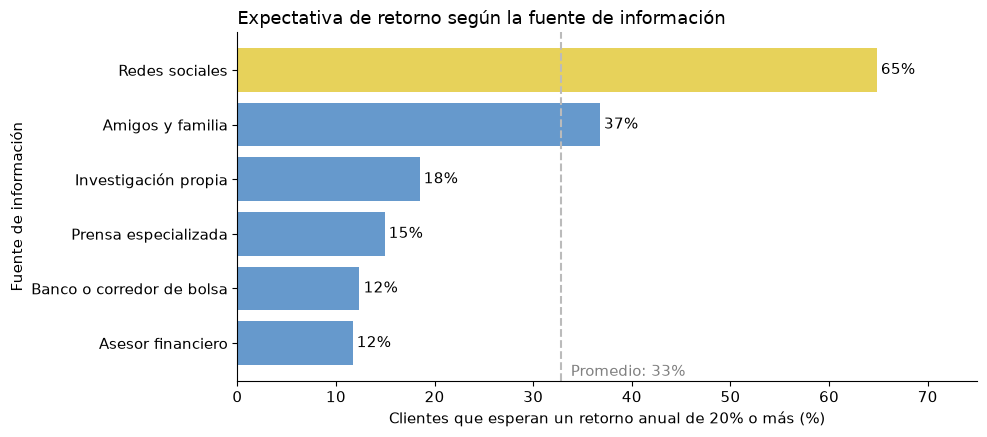

In [87]:
RETORNOS_ALTOS = ["20% a 30%", "Más de 30%"]
espera_retorno_alto = (encuesta.groupby("fuente_informacion", observed=True)["retorno_esperado_anual"]
                       .apply(lambda columna: columna.isin(RETORNOS_ALTOS).mean() * 100)
                       .sort_values())
promedio_general = encuesta["retorno_esperado_anual"].isin(RETORNOS_ALTOS).mean() * 100

colores = [AMARILLO if fuente == "Redes sociales" else AZUL_CLARO for fuente in espera_retorno_alto.index]
fig, ax = plt.subplots(figsize=(10, 4.5))
barras = ax.barh(espera_retorno_alto.index, espera_retorno_alto.values, color=colores)
ax.bar_label(barras, fmt="%.0f%%", padding=3)
ax.axvline(promedio_general, color=GRIS, linestyle="--")
ax.text(promedio_general + 1, -0.6, f"Promedio: {promedio_general:.0f}%", color="gray")
ax.set_xlim(0, 75)
ax.set_title("Expectativa de retorno según la fuente de información", loc="left")
ax.set_xlabel("Clientes que esperan un retorno anual de 20% o más (%)")
ax.set_ylabel("Fuente de información")
plt.tight_layout()
plt.savefig(CARPETA_SALIDAS / "grafico_2_retorno_por_fuente.png", dpi=150)
plt.show()

**Conclusión:** la fuente de información ordena las expectativas. El 65% de los que se informan por redes sociales espera ganar 20% o más por año (un retorno que ninguna cartera de la firma alcanza, como se vio en la 3.2), contra el 12% de los que se informan con un asesor financiero.

<h3 style='font-weight:bold; color:#0033BB;'>Gráfico 3 · La relación que se desarma al controlar: antes y después</h3>

Se usan dos paneles que **comparten el eje vertical** (`sharey=True`), porque en los dos se mide lo mismo (el riesgo efectivo, en la misma escala). Así la altura de las barras se puede comparar entre paneles. El eje horizontal no se comparte, porque en el panel de la izquierda está el fondo de emergencia y en el de la derecha la frecuencia de monitoreo.

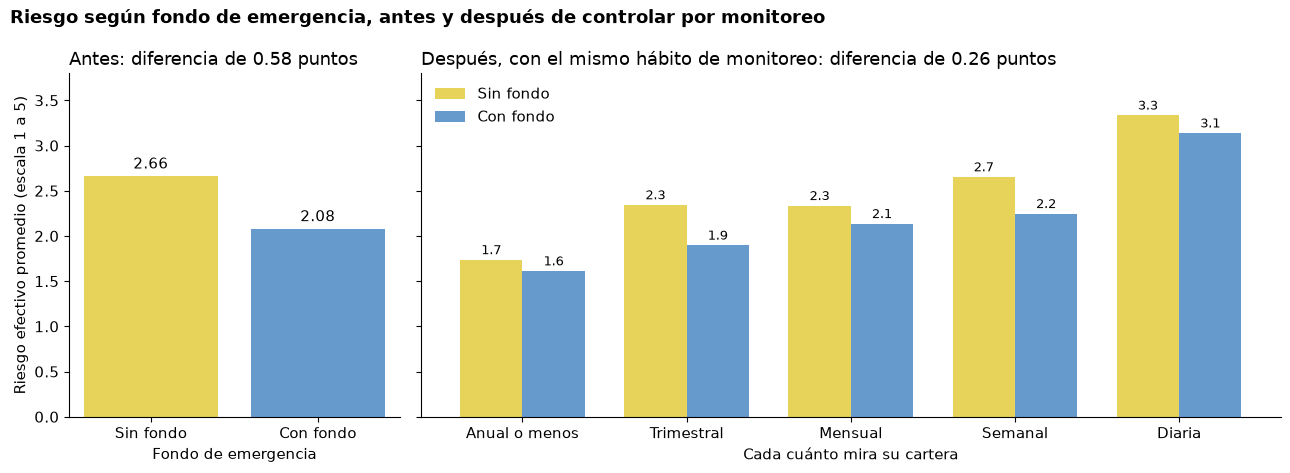

In [88]:
fig, (ax_antes, ax_despues) = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True,
                                           gridspec_kw={"width_ratios": [1, 2.6]})

# Panel izquierdo: ANTES de controlar
barras_antes = ax_antes.bar(["Sin fondo", "Con fondo"], diferencia_sin_controlar.values, color=[AMARILLO, AZUL_CLARO])
ax_antes.bar_label(barras_antes, fmt="%.2f", padding=3)
ax_antes.set_title(f"Antes: diferencia de {diferencia_original:.2f} puntos", loc="left")
ax_antes.set_xlabel("Fondo de emergencia")
ax_antes.set_ylabel("Riesgo efectivo promedio (escala 1 a 5)")

# Panel derecho: DESPUÉS, comparando dentro de cada frecuencia de monitoreo
posiciones = np.arange(len(ORDEN_MONITOREO))
ANCHO = 0.38
barras_sin = ax_despues.bar(posiciones - ANCHO / 2, riesgo_controlado["No"], ANCHO, color=AMARILLO, label="Sin fondo")
barras_con = ax_despues.bar(posiciones + ANCHO / 2, riesgo_controlado["Sí"], ANCHO, color=AZUL_CLARO, label="Con fondo")
ax_despues.bar_label(barras_sin, fmt="%.1f", padding=2, fontsize=9)
ax_despues.bar_label(barras_con, fmt="%.1f", padding=2, fontsize=9)
ax_despues.set_xticks(posiciones, ORDEN_MONITOREO)
ax_despues.set_title(f"Después, con el mismo hábito de monitoreo: diferencia de {diferencia_controlada:.2f} puntos", loc="left")
ax_despues.set_xlabel("Cada cuánto mira su cartera")
ax_despues.legend(frameon=False)

ax_antes.set_ylim(0, 3.8)
fig.suptitle("Riesgo según fondo de emergencia, antes y después de controlar por monitoreo",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.savefig(CARPETA_SALIDAS / "grafico_3_relacion_que_se_desarma.png", dpi=150)
plt.show()

**Conclusión:** a la izquierda parece que no tener fondo de emergencia lleva a carteras mucho más riesgosas. A la derecha, comparando clientes que miran su cartera con la misma frecuencia, la diferencia se achica a menos de la mitad, y lo que de verdad hace subir el riesgo es mirar la cartera más seguido: las barras crecen de izquierda a derecha en los dos colores.

<h3 style='font-weight:bold; color:#0033BB;'>Gráfico 4 · Composición de las carteras según el perfil declarado (Plotly)</h3>

In [89]:
cartera_con_perfil = pd.merge(cartera, clientes[["id_cliente", "perfil_autodeclarado"]], on="id_cliente")
composicion = (cartera_con_perfil.groupby(["perfil_autodeclarado", "categoria"], observed=True)["monto_usd"]
               .sum().reset_index())
composicion["% de la cartera"] = (composicion["monto_usd"]
                                  / composicion.groupby("perfil_autodeclarado", observed=True)["monto_usd"].transform("sum") * 100)

# Familias ordenadas de menor a mayor riesgo promedio
orden_familias = catalogo.groupby("categoria", observed=True)["nivel_riesgo"].mean().sort_values().index.tolist()
COLORES_FAMILIA = ["#BBBBBB", "#99B3CC", "#6699CC", "#336699", "#7CB8A4", "#C1A1D4", "#003366", "#E7D25A", "#BB3300"]

figura_composicion = px.bar(
    composicion, x="perfil_autodeclarado", y="% de la cartera", color="categoria",
    category_orders={"perfil_autodeclarado": PERFILES, "categoria": orden_familias},
    color_discrete_sequence=COLORES_FAMILIA,
    custom_data=["categoria", "monto_usd"],
    labels={"perfil_autodeclarado": "Perfil que el cliente dice tener", "% de la cartera": "Peso en la cartera total del grupo (%)",
            "categoria": "Familia de activo"},
    title="Composición de las carteras según el perfil declarado",
    height=500,
)
figura_composicion.update_traces(hovertemplate=(
    "<b>%{customdata[0]}</b><br>%{y:.1f}% de la cartera de los que se dicen %{x}<br>"
    "USD %{customdata[1]:,.0f}<extra></extra>"))
figura_composicion.update_layout(yaxis=dict(range=[0, 100], ticksuffix="%"))
figura_composicion.write_html(CARPETA_SALIDAS / "grafico_4_composicion.html", include_plotlyjs=True)
figura_composicion.show()

In [90]:
# Los números detrás del gráfico
composicion.pivot_table(index="categoria", columns="perfil_autodeclarado", values="% de la cartera",
                        observed=True).reindex(orden_familias)[PERFILES].round(1)

perfil_autodeclarado,Conservador,Moderado,Agresivo
categoria,,,
Efectivo,11.2,6.3,3.7
Renta fija local,37.4,29.5,23.1
Fondos,9.5,11.7,3.9
Inmobiliario,4.2,NaN,4.5
Renta fija corporativa,14.5,19.9,19.4
Previsional,14.2,12.4,12.8
Materias primas,6.0,5.7,14.6
Renta variable,2.1,13.8,10.3
Cripto,0.8,0.7,7.6


**Conclusión:** las diferencias van en la dirección esperada, pero son más chicas de lo que sugieren las etiquetas. Los que se dicen agresivos tienen más cripto (7,6% contra 0,8%) y más oro (14,6% contra 6,0%) que los conservadores, pero igual dos tercios de su cartera están en efectivo, renta fija, fondos y previsión. Y los moderados tienen más renta variable (13,8%) que los agresivos (10,3%).

<h3 style='font-weight:bold; color:#0033BB;'>Gráfico 5 · Una distribución donde el promedio y la mediana cuentan historias distintas</h3>

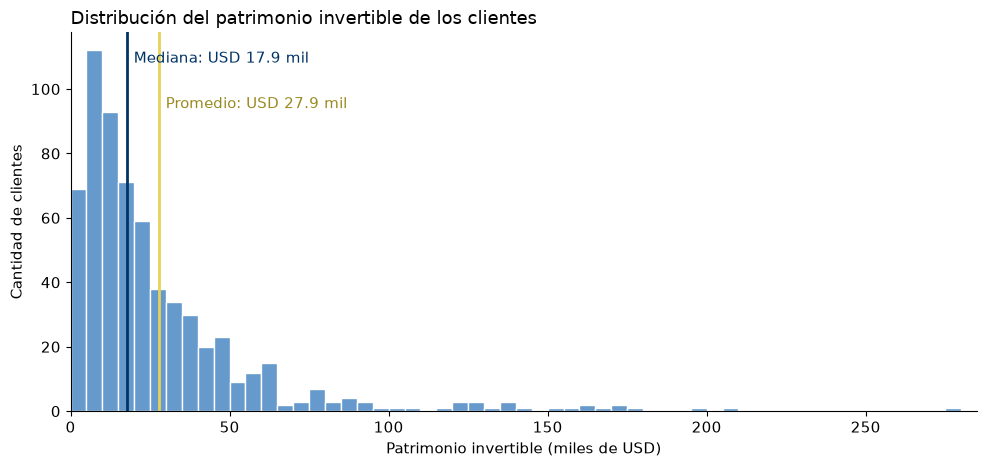

El 10% de clientes con más patrimonio concentra el 37% del patrimonio total


In [91]:
patrimonio_miles = clientes["patrimonio_invertible_usd"] / 1_000
promedio_patrimonio = patrimonio_miles.mean()
mediana_patrimonio = patrimonio_miles.median()
porcentaje_debajo_promedio = (patrimonio_miles < promedio_patrimonio).mean() * 100
diez_mayores = clientes["patrimonio_invertible_usd"].nlargest(int(len(clientes) * 0.10)).sum()
participacion_top10 = diez_mayores / clientes["patrimonio_invertible_usd"].sum() * 100

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.hist(patrimonio_miles, bins=np.arange(0, 290, 5), color=AZUL_CLARO, edgecolor="white")
ax.axvline(mediana_patrimonio, color=AZUL, linewidth=2)
ax.axvline(promedio_patrimonio, color=AMARILLO, linewidth=2)
ax.text(mediana_patrimonio + 2, ax.get_ylim()[1] * 0.92, f"Mediana: USD {mediana_patrimonio:.1f} mil", color=AZUL)
ax.text(promedio_patrimonio + 2, ax.get_ylim()[1] * 0.80, f"Promedio: USD {promedio_patrimonio:.1f} mil", color="#9A8A20")
ax.set_xlim(0, 285)
ax.set_title("Distribución del patrimonio invertible de los clientes", loc="left")
ax.set_xlabel("Patrimonio invertible (miles de USD)")
ax.set_ylabel("Cantidad de clientes")
plt.tight_layout()
plt.savefig(CARPETA_SALIDAS / "grafico_5_patrimonio.png", dpi=150)
plt.show()

print(f"El 10% de clientes con más patrimonio concentra el {participacion_top10:.0f}% del patrimonio total")

**Conclusión:** el promedio (USD 27.900) está muy por encima de la mediana (USD 17.900) porque unos pocos clientes con patrimonios de más de USD 100.000 lo tiran para arriba: el 10% más rico concentra el 37% del patrimonio. Si la firma diseña sus productos para el "cliente promedio", los diseña para alguien más rico que dos de cada tres clientes; para describir al cliente típico hay que usar la mediana.

**Conclusiones de la Etapa 4**
1. **Brecha:** solo los conservadores coinciden mayoritariamente con su cartera; de los que se dicen agresivos, apenas un tercio lo es.
2. **Fuente de información:** el 65% de los que se informan por redes espera 20% o más anual, contra el 12% de los que consultan a un asesor.
3. **Relación que se desarma:** la diferencia de riesgo entre tener o no fondo de emergencia se achica a menos de la mitad al comparar clientes con el mismo hábito de monitoreo.
4. **Composición:** los que se dicen agresivos tienen más cripto y oro, pero igual dos tercios de su cartera están en activos de riesgo bajo o medio.
5. **Distribución del patrimonio:** promedio de USD 27.900 contra una mediana de USD 17.900; el 10% más rico tiene el 37% del patrimonio.

---
<h1 style='font-weight:bold; color:#003366;'>Etapa 5 · Perfiles y carteras modelo</h1>
<h3 style='font-weight:bold; color:#0033BB;'>5.1 Nuevos perfiles, construidos con comportamiento y situación financiera</h3>

Las etapas anteriores mostraron que la autodeclaración no sirve para predecir la cartera (49% de desajuste) y que la edad y otras variables demográficas explican muy poco. Lo que sí se asocia con cómo invierte la gente es el **comportamiento** (qué hace con su plata, cada cuánto mira la cartera, de dónde se informa) y su **situación financiera** (si tiene un colchón para emergencias y cuánto patrimonio tiene).

Con eso se definen **cinco perfiles**, que se asignan en este orden (cada cliente queda en el primero que cumple):

| Orden | Perfil | Regla | Por qué |
|---|---|---|---|
| 1 | **Guardián del colchón** | 40% o más de su cartera en dólares en caja | Comportamiento: tiene la plata quieta, perdiendo contra la inflación (3.2.4) |
| 2 | **Inversor de pantalla** | Se informa por redes sociales **y** mira su cartera todos los días o todas las semanas | Comportamiento: es el grupo con más riesgo y con expectativas imposibles (3.2.3 y 3.3.5) |
| 3 | **Ahorrista sin red** | No tiene fondo de emergencia | Situación financiera: ante una urgencia tiene que vender, así que necesita liquidez |
| 4 | **Patrimonio consolidado** | Tiene fondo de emergencia **y** patrimonio de USD 60.000 o más | Situación financiera: puede acceder a instrumentos con mínimos altos y esperar |
| 5 | **Ahorrista previsor** | Tiene fondo de emergencia y patrimonio menor a USD 60.000 | Situación financiera ordenada, con patrimonio medio |

El orden importa: primero van los comportamientos que más hay que corregir (la plata quieta y la especulación), porque definen qué necesita el cliente aunque tenga o no fondo. El corte de USD 60.000 deja en el perfil consolidado a los clientes que pueden respetar los mínimos de los instrumentos más caros (fideicomisos, notas en UI y obligaciones negociables, ver 5.2).

In [92]:
UMBRAL_CAJA_PERFIL = 0.40
PATRIMONIO_CONSOLIDADO_USD = 60_000
MONITOREO_FRECUENTE = ["Diaria", "Semanal"]
NOMBRES_PERFILES = ["Guardián del colchón", "Inversor de pantalla", "Ahorrista sin red",
                    "Ahorrista previsor", "Patrimonio consolidado"]


def asignar_perfil(cliente):
    """Devuelve el nuevo perfil de un cliente según su comportamiento y su situación financiera."""
    if cliente["peso_caja"] >= UMBRAL_CAJA_PERFIL:
        return "Guardián del colchón"
    if cliente["fuente_informacion"] == "Redes sociales" and cliente["frecuencia_monitoreo"] in MONITOREO_FRECUENTE:
        return "Inversor de pantalla"
    if cliente["tiene_fondo_emergencia"] == "No":
        return "Ahorrista sin red"
    if cliente["patrimonio_invertible_usd"] >= PATRIMONIO_CONSOLIDADO_USD:
        return "Patrimonio consolidado"
    return "Ahorrista previsor"


clientes["perfil_nuevo"] = clientes.apply(asignar_perfil, axis=1)
clientes["perfil_nuevo"].value_counts().reindex(NOMBRES_PERFILES)

perfil_nuevo
Guardián del colchón       61
Inversor de pantalla      153
Ahorrista sin red         219
Ahorrista previsor        177
Patrimonio consolidado     23
Name: count, dtype: int64

In [93]:
# Variables de cartera que faltan para describir los perfiles: peso en cripto y en instrumentos poco líquidos
cartera["es_poco_liquido"] = cartera["liquidez"].isin(["Muy baja", "Baja"])
peso_poco_liquido = cartera[cartera["es_poco_liquido"]].groupby("id_cliente")["peso"].sum()
peso_cripto = cartera[cartera["id_instrumento"] == 13].groupby("id_cliente")["peso"].sum()
clientes["peso_poco_liquido"] = clientes["id_cliente"].map(peso_poco_liquido).fillna(0)
clientes["peso_cripto"] = clientes["id_cliente"].map(peso_cripto).fillna(0)

descripcion_perfiles = clientes.groupby("perfil_nuevo").agg(
    clientes=("id_cliente", "count"),
    patrimonio_total_usd=("patrimonio_invertible_usd", "sum"),
    patrimonio_mediano_usd=("patrimonio_invertible_usd", "median"),
    riesgo_efectivo=("riesgo_efectivo", "mean"),
    retorno_cartera_pct=("retorno_cartera", "mean"),
    pct_en_caja=("peso_caja", "mean"),
    pct_poco_liquido=("peso_poco_liquido", "mean"),
    pct_cripto=("peso_cripto", "mean"),
    meses_cubiertos=("meses_gastos_cubiertos", "mean"),
    puntaje_test=("puntaje_test_conocimiento", "mean"),
    edad_mediana=("edad", "median"),
).reindex(NOMBRES_PERFILES)

descripcion_perfiles.insert(1, "% de clientes", descripcion_perfiles["clientes"] / len(clientes) * 100)
descripcion_perfiles.insert(3, "% del patrimonio",
                            descripcion_perfiles["patrimonio_total_usd"] / descripcion_perfiles["patrimonio_total_usd"].sum() * 100)
for columna in ["retorno_cartera_pct", "pct_en_caja", "pct_poco_liquido", "pct_cripto"]:
    descripcion_perfiles[columna] = descripcion_perfiles[columna] * 100

descripcion_perfiles.round(1).T

perfil_nuevo,Guardián del colchón,Inversor de pantalla,Ahorrista sin red,Ahorrista previsor,Patrimonio consolidado
clientes,61.0,153.0,219.0,177.0,23.0
% de clientes,9.6,24.2,34.6,28.0,3.6
patrimonio_total_usd,1441368.3,4136671.0,5770875.4,3556805.1,2773032.9
% del patrimonio,8.2,23.4,32.6,20.1,15.7
patrimonio_mediano_usd,15000.0,17500.0,16800.0,17100.0,123400.0
riesgo_efectivo,1.2,3.2,2.5,2.0,2.1
retorno_cartera_pct,1.7,8.1,6.0,5.2,5.0
pct_en_caja,66.8,1.5,3.5,4.8,4.0
pct_poco_liquido,19.0,46.2,59.4,59.1,57.8
pct_cripto,0.1,9.8,1.4,0.2,0.1


In [94]:
# Otros rasgos de cada perfil, en % de sus clientes
rasgos = clientes.groupby("perfil_nuevo").agg(
    pct_redes=("fuente_informacion", lambda columna: (columna == "Redes sociales").mean() * 100),
    pct_mira_a_diario=("frecuencia_monitoreo", lambda columna: (columna == "Diaria").mean() * 100),
    pct_espera_20_o_mas=("retorno_esperado_anual", lambda columna: columna.isin(RETORNOS_ALTOS).mean() * 100),
    pct_sin_fondo=("tiene_fondo_emergencia", lambda columna: (columna == "No").mean() * 100),
    pct_con_deudas=("tiene_deudas", lambda columna: (columna == "Sí").mean() * 100),
).reindex(NOMBRES_PERFILES)
rasgos.round(0)

,pct_redes,pct_mira_a_diario,pct_espera_20_o_mas,pct_sin_fondo,pct_con_deudas
perfil_nuevo,,,,,
Guardián del colchón,20.0,5.0,16.0,36.0,36.0
Inversor de pantalla,100.0,83.0,69.0,67.0,43.0
Ahorrista sin red,3.0,8.0,27.0,100.0,43.0
Ahorrista previsor,5.0,5.0,17.0,0.0,41.0
Patrimonio consolidado,4.0,4.0,13.0,0.0,52.0


In [95]:
# ¿Los nuevos perfiles son lo mismo que la autodeclaración con otro nombre? No: cada perfil mezcla los tres.
(pd.crosstab(clientes["perfil_nuevo"], clientes["perfil_autodeclarado"], normalize="index") * 100).reindex(NOMBRES_PERFILES).round(0)

perfil_autodeclarado,Agresivo,Conservador,Moderado
perfil_nuevo,,,
Guardián del colchón,13.0,66.0,21.0
Inversor de pantalla,42.0,27.0,30.0
Ahorrista sin red,19.0,50.0,31.0
Ahorrista previsor,11.0,62.0,27.0
Patrimonio consolidado,9.0,57.0,35.0


**Los cinco perfiles, con números:**

- **Guardián del colchón (61 clientes, 10%):** tiene en promedio el 67% de su cartera en dólares en caja, rindiendo 0%. Es el perfil con menor riesgo efectivo (1,2) y peor retorno (1,7% por año, por debajo de la inflación de EE.UU.). Dos de cada tres se declaran conservadores: confunden "no perder nominalmente" con "no perder".
- **Inversor de pantalla (153 clientes, 24%):** se informa por redes y mira su cartera a diario o cada semana. Tiene el riesgo efectivo más alto (3,2), la mayor exposición a cripto (10% en promedio) y el puntaje del test más bajo (3,5 sobre 10). Casi 7 de cada 10 esperan ganar 20% o más por año, y dos de cada tres no tienen fondo de emergencia.
- **Ahorrista sin red (219 clientes, 35%):** no tiene fondo de emergencia, y aun así **el 59% de su cartera está en instrumentos de los que no puede salir rápido** (plazos fijos, fideicomisos, AFAP, inmuebles). Ante una urgencia tendría que vender perdiendo, o no podría vender. Es justo el caso que la consigna marca como problema.
- **Ahorrista previsor (177 clientes, 28%):** tiene fondo de emergencia (más de 6 meses de gastos en promedio) y patrimonio medio. Su riesgo es el más bajo después del colchón (2,0) y es el grupo más ordenado.
- **Patrimonio consolidado (23 clientes, 4%):** pocos clientes, pero con un patrimonio mediano de USD 123.000 representan el 16% de todo el patrimonio. Tiene fondo y puede acceder a instrumentos con mínimos altos.

Cada perfil mezcla clientes que se declaran conservadores, moderados y agresivos: **los nuevos perfiles miden algo distinto de lo que el cliente dice de sí mismo.**

<h3 style='font-weight:bold; color:#0033BB;'>5.2 Una cartera modelo por perfil</h3>

Criterios de armado:
1. **Mínimos de inversión:** cada instrumento tiene un monto mínimo de entrada. Si un cliente pone el X% de su patrimonio en un instrumento, ese X% tiene que superar el mínimo. Por eso, a los perfiles con patrimonios chicos no se les asignan instrumentos con mínimos altos (notas en UI, fideicomisos, obligaciones negociables, inmuebles).
2. **Liquidez:** un cliente sin fondo de emergencia no puede tener una parte grande de su cartera en instrumentos de los que no puede salir. Para los perfiles donde hay muchos clientes sin fondo (colchón, pantalla y sin red) se pone como límite **20% en instrumentos de liquidez baja o muy baja**.
3. **El objetivo de cada perfil:**
   - *Colchón:* sacar los dólares de la caja y ponerlos a rendir sin asustar al cliente: mayoría de instrumentos de riesgo 1 y 2, y algo de ETF.
   - *Pantalla:* encauzar su gusto por el riesgo hacia una cartera diversificada (ETF global en lugar de apuestas individuales), con un tope de 5% en cripto.
   - *Sin red:* primero construir el colchón con instrumentos líquidos (fondo local y letras del BCU se pueden vender rápido) y recién después algo de crecimiento.
   - *Previsor:* equilibrio entre renta fija en pesos y dólares, renta variable y ahorro previsional de largo plazo.
   - *Consolidado:* diversificación completa, incluyendo los instrumentos de mínimos altos que los demás no pueden comprar.

In [96]:
# Cartera modelo de cada perfil: {id_instrumento: peso}
CARTERAS_MODELO = {
    "Guardián del colchón":   {2: 0.20, 3: 0.25, 5: 0.30, 9: 0.25},
    "Inversor de pantalla":   {9: 0.40, 10: 0.10, 13: 0.05, 5: 0.20, 3: 0.15, 2: 0.10},
    "Ahorrista sin red":      {5: 0.40, 3: 0.30, 9: 0.20, 2: 0.10},
    "Ahorrista previsor":     {9: 0.30, 10: 0.05, 3: 0.20, 1: 0.15, 2: 0.10, 5: 0.10, 8: 0.10},
    "Patrimonio consolidado": {9: 0.30, 10: 0.05, 6: 0.15, 7: 0.15, 4: 0.15, 3: 0.10, 12: 0.05, 2: 0.05},
}
PERFILES_CON_LIMITE_LIQUIDEZ = ["Guardián del colchón", "Inversor de pantalla", "Ahorrista sin red"]
LIMITE_POCO_LIQUIDO = 0.20

# Monto mínimo de cada instrumento, en dólares
catalogo["minimo_usd"] = catalogo["inversion_minima"] * catalogo["moneda"].astype(str).map(DOLARES_POR_UNIDAD)

tabla_carteras = pd.DataFrame(CARTERAS_MODELO).fillna(0) * 100
tabla_carteras.index = tabla_carteras.index.map(NOMBRES_CORTOS)
tabla_carteras = tabla_carteras.loc[tabla_carteras.sum(axis=1).sort_values(ascending=False).index]
print("¿Cada cartera suma 100%?", (tabla_carteras.sum().round(6) == 100).all())
tabla_carteras.round(0)

¿Cada cartera suma 100%? True


,Guardián del colchón,Inversor de pantalla,Ahorrista sin red,Ahorrista previsor,Patrimonio consolidado
ETF global,25.0,40.0,20.0,30.0,30.0
Letras BCU,25.0,15.0,30.0,20.0,10.0
Fondo local,30.0,20.0,40.0,10.0,0.0
PF dólares,20.0,10.0,10.0,10.0,5.0
Acciones exterior,0.0,10.0,0.0,5.0,5.0
PF pesos,0.0,0.0,0.0,15.0,0.0
Fideicomiso,0.0,0.0,0.0,0.0,15.0
Oblig. negociables,0.0,0.0,0.0,0.0,15.0
Notas UI,0.0,0.0,0.0,0.0,15.0
AFAP voluntario,0.0,0.0,0.0,10.0,0.0


In [97]:
datos_instrumento = catalogo.set_index("id_instrumento")


def armar_tabla_cartera(pesos):
    """Devuelve la cartera modelo como tabla, con los datos de cada instrumento."""
    tabla = datos_instrumento.loc[list(pesos.keys()),
                                  ["nombre_corto", "retorno_usd", "volatilidad_anual", "nivel_riesgo", "liquidez", "minimo_usd"]].copy()
    tabla["peso"] = list(pesos.values())
    return tabla


controles = []
for perfil, pesos in CARTERAS_MODELO.items():
    tabla = armar_tabla_cartera(pesos)
    patrimonio_minimo = (tabla["minimo_usd"] / tabla["peso"]).max()   # el instrumento que más exige
    peso_poco_liquido_modelo = tabla.loc[tabla["liquidez"].isin(["Muy baja", "Baja"]), "peso"].sum()
    clientes_del_perfil = clientes[clientes["perfil_nuevo"] == perfil]
    controles.append({
        "perfil": perfil,
        "patrimonio mínimo para respetar los mínimos (USD)": round(patrimonio_minimo),
        "% de sus clientes que lo alcanza": round((clientes_del_perfil["patrimonio_invertible_usd"] >= patrimonio_minimo).mean() * 100, 1),
        "% poco líquido": round(peso_poco_liquido_modelo * 100),
        "cumple el límite de liquidez": (peso_poco_liquido_modelo <= LIMITE_POCO_LIQUIDO) if perfil in PERFILES_CON_LIMITE_LIQUIDEZ else "no aplica (tienen fondo)",
    })
pd.DataFrame(controles).set_index("perfil")

,patrimonio mínimo para respetar los mínimos (USD),% de sus clientes que lo alcanza,% poco líquido,cumple el límite de liquidez
perfil,,,,
Guardián del colchón,4673,82.0,20,True
Inversor de pantalla,7788,76.5,10,True
Ahorrista sin red,5000,87.2,10,True
Ahorrista previsor,10000,74.6,35,no aplica (tienen fondo)
Patrimonio consolidado,40810,100.0,35,no aplica (tienen fondo)


**Control de las restricciones:**
- **Mínimos:** las carteras de los perfiles chicos solo necesitan entre USD 4.700 y USD 10.000 de patrimonio para respetar todos los mínimos, y entre el 75% y el 87% de sus clientes los supera. La del perfil consolidado necesita unos USD 41.000 (por el fideicomiso), y todos sus clientes los tienen, porque el perfil empieza en USD 60.000. **Los inmuebles de renta quedaron afuera de todas las carteras:** con un mínimo de USD 80.000, para que pesaran aunque sea un 20% haría falta un patrimonio de USD 400.000, y ningún cliente de la firma llega.
- **Liquidez:** en los tres perfiles con muchos clientes sin fondo, la parte poco líquida queda en 10% a 20%, dentro del límite. Hoy el ahorrista sin red tiene casi el 60%.
- Para los pocos clientes que no llegan al patrimonio mínimo de su cartera, la recomendación es una versión simplificada con menos instrumentos (por ejemplo, empezar solo con fondo local y plazo fijo en dólares) e ir sumando a medida que crece el patrimonio.

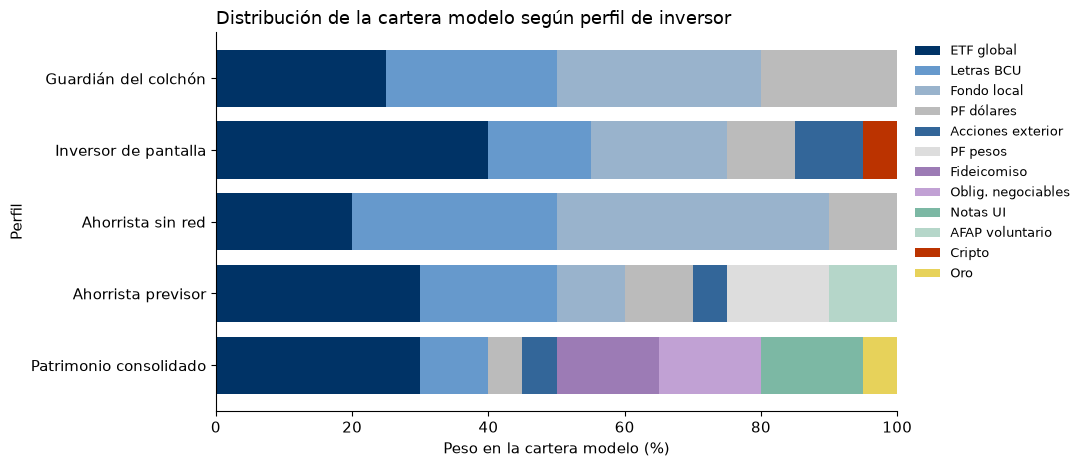

In [98]:
# Gráfico de las carteras modelo
COLORES_INSTRUMENTOS = {
    "Fondo local": "#99B3CC", "Letras BCU": "#6699CC", "PF dólares": "#BBBBBB", "PF pesos": "#DDDDDD",
    "ETF global": "#003366", "Acciones exterior": "#336699", "Cripto": "#BB3300", "Notas UI": "#7CB8A4",
    "Oblig. negociables": "#C1A1D4", "Fideicomiso": "#9C7BB5", "AFAP voluntario": "#B5D6C9", "Oro": "#E7D25A",
}
fig, ax = plt.subplots(figsize=(11, 4.8))
izquierda = np.zeros(len(NOMBRES_PERFILES))
for instrumento in tabla_carteras.index:
    valores = tabla_carteras.loc[instrumento, NOMBRES_PERFILES].values
    ax.barh(NOMBRES_PERFILES, valores, left=izquierda, color=COLORES_INSTRUMENTOS[instrumento], label=instrumento)
    izquierda += valores
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_title("Distribución de la cartera modelo según perfil de inversor", loc="left")
ax.set_xlabel("Peso en la cartera modelo (%)")
ax.set_ylabel("Perfil")
ax.legend(ncol=1, bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig(CARPETA_SALIDAS / "5_2_carteras_modelo.png", dpi=150)
plt.show()

<h3 style='font-weight:bold; color:#0033BB;'>5.3 Retorno esperado y volatilidad de cada cartera modelo</h3>

- **Retorno esperado:** promedio de los retornos en dólares de cada instrumento (calculados en la 3.2.3), ponderado por su peso en la cartera.
- **Retorno real:** se le descuenta la inflación de Estados Unidos (2,7%), porque el retorno está en dólares: $(1 + \text{retorno nominal}) / (1 + \text{inflación}) - 1$. Con el supuesto de devaluación usado en la 3.2.3, el retorno real en pesos da lo mismo.
- **Volatilidad:** el catálogo trae la volatilidad de cada instrumento pero no cómo se mueven unos respecto de otros (las correlaciones), que hacen falta para calcular la volatilidad exacta de una cartera. Por eso se dan **dos límites**:
  - **Máxima:** si todos los instrumentos subieran y bajaran a la vez (correlación 1), la volatilidad de la cartera sería el promedio ponderado de las volatilidades. Es el peor caso.
  - **Mínima:** si se movieran de forma totalmente independiente (correlación 0), sería $\sqrt{\sum (\text{peso} \times \text{volatilidad})^2}$.

  La volatilidad real está entre los dos.

In [99]:
def calcular_metricas_cartera(pesos):
    """Devuelve el retorno nominal y real, la volatilidad mínima y máxima y el riesgo de una cartera."""
    tabla = armar_tabla_cartera(pesos)
    retorno_nominal = (tabla["peso"] * tabla["retorno_usd"]).sum()
    return {
        "retorno nominal en USD (%)": retorno_nominal * 100,
        "retorno real (%)": ((1 + retorno_nominal) / (1 + INFLACION_EEUU) - 1) * 100,
        "volatilidad mínima (%)": np.sqrt(((tabla["peso"] * tabla["volatilidad_anual"]) ** 2).sum()) * 100,
        "volatilidad máxima (%)": (tabla["peso"] * tabla["volatilidad_anual"]).sum() * 100,
        "riesgo efectivo (1 a 5)": (tabla["peso"] * tabla["nivel_riesgo"]).sum(),
    }


metricas_modelo = pd.DataFrame({perfil: calcular_metricas_cartera(pesos) for perfil, pesos in CARTERAS_MODELO.items()}).T

# Comparación con lo que tienen hoy los clientes de cada perfil
hoy = clientes.groupby("perfil_nuevo").agg(retorno_hoy=("retorno_cartera", "mean"), riesgo_hoy=("riesgo_efectivo", "mean"))
metricas_modelo["retorno nominal hoy (%)"] = hoy["retorno_hoy"] * 100
metricas_modelo["riesgo efectivo hoy"] = hoy["riesgo_hoy"]
metricas_modelo.round(2)

,retorno nominal en USD (%),retorno real (%),volatilidad mínima (%),volatilidad máxima (%),riesgo efectivo (1 a 5),retorno nominal hoy (%),riesgo efectivo hoy
Guardián del colchón,5.92,3.13,4.01,5.44,2.05,1.71,1.23
Inversor de pantalla,8.17,5.33,7.37,12.83,3.00,8.11,3.20
Ahorrista sin red,5.87,3.09,3.48,5.11,2.00,5.98,2.49
Ahorrista previsor,6.45,3.65,4.78,7.17,2.40,5.24,2.02
Patrimonio consolidado,7.91,5.08,4.99,8.97,3.00,5.05,2.12


**Lectura de la tabla:**
- **Guardián del colchón:** pasa de rendir 1,7% a 5,9% en dólares, con un riesgo que sigue siendo bajo (de 1,2 a 2,0). En términos reales pasa de perder poder de compra a ganar un 3,1% por año.
- **Inversor de pantalla:** mantiene su retorno (8,1% hoy, 8,2% en el modelo) pero bajando el riesgo de 3,2 a 3,0 y con una cartera diversificada: la volatilidad máxima es del 13% (menos que un ETF), en vez de depender de apuestas concentradas como la cripto.
- **Ahorrista sin red:** mantiene un retorno parecido al actual pero con una cartera que puede vender rápido si tiene una urgencia, y con la volatilidad más baja de todas.
- **Ahorrista previsor y patrimonio consolidado:** mejoran su retorno actual (de 5,2% a 6,5% y de 5,0% a 7,9%), con retornos reales de 3,7% y 5,1% por año y volatilidades moderadas.

Ninguna cartera promete más de 9% nominal. **Es una conversación que la firma tiene que tener con los clientes que esperan 30%:** con lo que ofrece el mercado, no es posible sin un riesgo enorme.

<h3 style='font-weight:bold; color:#0033BB;'>5.4 Qué preguntas debería tener el formulario de perfilado</h3>

Para cada pregunta de la encuesta se mide **cuánto cambia el riesgo real de la cartera según lo que contesta el cliente**: la diferencia entre el grupo de respuesta con más riesgo y el grupo con menos. Si la pregunta casi no separa a los clientes, no sirve para perfilar.

In [100]:
PREGUNTAS = ["perfil_autodeclarado", "tolerancia_perdida_maxima", "horizonte_inversion", "frecuencia_monitoreo",
             "retorno_esperado_anual", "reaccion_caida_20", "objetivo_principal", "fuente_informacion",
             "conocimiento_autopercibido", "puntaje_test_conocimiento", "anios_experiencia_invirtiendo",
             "tiene_fondo_emergencia", "tiene_deudas", "prioridad_criptomonedas", "prioridad_plazo_fijo"]
PREGUNTAS_NUMERICAS = ["puntaje_test_conocimiento", "anios_experiencia_invirtiendo"]
MINIMO_CLIENTES_GRUPO = 10

poder_de_la_pregunta = []
for pregunta in PREGUNTAS:
    respuestas = clientes[pregunta]
    if pregunta in PREGUNTAS_NUMERICAS:   # las numéricas se agrupan en tres tramos
        respuestas = pd.qcut(respuestas, 3, duplicates="drop")
    resumen = clientes.groupby(respuestas, observed=True)["riesgo_efectivo"].agg(["mean", "count"])
    resumen = resumen[resumen["count"] >= MINIMO_CLIENTES_GRUPO]   # se ignoran grupos muy chicos
    poder_de_la_pregunta.append({
        "pregunta": pregunta,
        "diferencia de riesgo entre respuestas": resumen["mean"].max() - resumen["mean"].min(),
        "respuesta con más riesgo": resumen["mean"].idxmax(),
        "respuesta con menos riesgo": resumen["mean"].idxmin(),
    })

pd.DataFrame(poder_de_la_pregunta).sort_values("diferencia de riesgo entre respuestas", ascending=False).round(2)

,pregunta,diferencia de riesgo entre respuestas,respuesta con más riesgo,respuesta con menos riesgo
1,tolerancia_perdida_maxima,1.93,Más de 20%,No aceptaría ninguna pérdida
3,frecuencia_monitoreo,1.63,Diaria,Anual o menos
5,reaccion_caida_20,1.41,Vendería todo,Compraría más
4,retorno_esperado_anual,1.09,Más de 30%,Menos de 5%
7,fuente_informacion,1.03,Redes sociales,Asesor financiero
0,perfil_autodeclarado,0.93,Agresivo,Conservador
14,prioridad_plazo_fijo,0.75,7,3
13,prioridad_criptomonedas,0.69,1,3
11,tiene_fondo_emergencia,0.58,No,Sí
9,puntaje_test_conocimiento,0.50,"(-0.001, 4.0]","(5.0, 10.0]"


In [101]:
print(f"Clientes que ponen las criptomonedas como su inversión preferida (prioridad 1): "
      f"{(encuesta['prioridad_criptomonedas'] == 1).mean():.0%}")
print(f"Clientes que efectivamente tienen criptomonedas: {(clientes['peso_cripto'] > 0).mean():.0%}")
print()
print("Riesgo efectivo según lo que dicen que harían ante una caída de 20%:")
print(clientes.groupby("reaccion_caida_20", observed=True)["riesgo_efectivo"].mean().sort_values().round(2).to_string())

Clientes que ponen las criptomonedas como su inversión preferida (prioridad 1): 85%
Clientes que efectivamente tienen criptomonedas: 7%

Riesgo efectivo según lo que dicen que harían ante una caída de 20%:
reaccion_caida_20
Compraría más         1.82
No haría nada         2.21
Sin respuesta         2.35
Vendería una parte    2.89
Vendería todo         3.23


**Lo que muestran los datos:**
- Las preguntas que **más separan** a los clientes son la **tolerancia a pérdidas**, la **frecuencia de monitoreo**, la reacción ante una caída, el retorno esperado y la fuente de información. Todas preguntan por actitudes y hábitos concretos.
- La **reacción ante una caída de 20% predice al revés**: los que dicen que "comprarían más" tienen las carteras **más conservadoras** (1,82) y los que dicen que "venderían todo", las más riesgosas (3,23). La pregunta separa, pero lo que la gente contesta sobre una situación hipotética no coincide con lo que hace.
- El **perfil autodeclarado** separa menos que las anteriores y falla en la mitad de los casos (3.1).
- El **horizonte**, el **objetivo**, el **conocimiento autopercibido** y los **años de experiencia** casi no cambian el riesgo de la cartera.
- Las **prioridades** separan algo (la de plazo fijo, 0,75), pero son una preferencia declarada que no se cumple: el 85% pone a las criptomonedas como su inversión preferida, pero solo el 7% tiene criptomonedas. Además son siete preguntas, lo que alarga el formulario.

**Propuesta para el nuevo formulario:**

| Decisión | Pregunta | Justificación |
|---|---|---|
| **Mantener** | Tolerancia a la pérdida máxima | Es la que más separa el riesgo real |
| **Mantener** | Frecuencia de monitoreo | Separa casi tanto como la tolerancia y es la variable que explica la relación con el fondo de emergencia (3.3.5) |
| **Mantener** | Fuente de información | Identifica al inversor de pantalla y predice expectativas irreales (gráfico 2) |
| **Mantener** | Fondo de emergencia y meses cubiertos | Define cuánta liquidez necesita la cartera (5.2) |
| **Mantener** | Retorno esperado | No para perfilar sino para detectar expectativas imposibles y conversarlas (3.2.3) |
| **Mantener** | Test objetivo de conocimiento | Mide lo que el cliente sabe de verdad, a diferencia del autopercibido |
| **Reformular** | Reacción ante una caída de 20% | Predice al revés. Cambiarla por una pregunta sobre **lo que hizo** en una caída real ("¿qué hiciste en la última baja fuerte de tus inversiones?") |
| **Sacar** | Perfil autodeclarado | Falla en la mitad de los casos, y que el cliente se ponga una etiqueta genera el problema legal de la 3.1.2 |
| **Sacar** | Conocimiento autopercibido | No predice el riesgo y el test ya mide el conocimiento real |
| **Sacar** | Las siete prioridades | Preferencias que no se cumplen (85% prefiere cripto, 7% tiene) |
| **Sacar** | Horizonte de inversión | Casi no separa el riesgo de la cartera |
| **Agregar** | Patrimonio fuera de la firma | La firma solo ve una parte (lo declarado es 1,43 veces lo conocido, 1.7) |
| **Agregar** | Gastos grandes previstos en los próximos 12 meses | Para saber cuánta liquidez necesita el cliente además del fondo de emergencia |

Además, el formulario tiene que tener **validaciones**: rangos de edad posibles, montos numéricos sin texto, opciones cerradas para las categorías y la pregunta de meses cubiertos solo para quien tiene fondo. Así se evitan los problemas de calidad de la Etapa 1.

**Resumen de la Etapa 5**
1. **Cinco perfiles nuevos**, construidos con comportamiento y situación financiera: Guardián del colchón (61 clientes), Inversor de pantalla (153), Ahorrista sin red (219), Ahorrista previsor (177) y Patrimonio consolidado (23 clientes con el 16% del patrimonio).
2. **Una cartera modelo por perfil**, que respeta los mínimos de inversión y limita a 20% la parte poco líquida en los perfiles con muchos clientes sin fondo de emergencia.
3. **Retornos esperados** de entre 5,9% y 8,2% en dólares (3,1% a 5,3% real), con volatilidades máximas de entre 5% y 13%. El guardián del colchón pasa de perder poder de compra a ganarle a la inflación.
4. **Nuevo formulario:** mantener tolerancia, monitoreo, fuente, fondo de emergencia, retorno esperado y test; reformular la reacción ante caídas; sacar el perfil autodeclarado, el conocimiento autopercibido, las prioridades y el horizonte; agregar patrimonio externo y gastos previstos.

---
<h1 style='font-weight:bold; color:#003366;'>Conclusión general</h1>

**¿Cuántos clientes tienen una cartera que no se parece a lo que dijeron ser?** 313 de 633, **el 49,4%**. Entre ellos hay **19 clientes que se dicen conservadores y tienen carteras agresivas** (un riesgo legal para la firma) y **44 que se dicen agresivos y tienen carteras conservadoras** (una oportunidad comercial perdida).

**¿Quiénes son?** Lo que mejor explica cómo invierte un cliente no es lo que dice de sí mismo ni su edad, sino su **comportamiento**: de dónde se informa, cada cuánto mira su cartera y cuánta pérdida tolera. Por eso se proponen **cinco perfiles basados en comportamiento y situación financiera**, cada uno con una cartera modelo que respeta los mínimos de inversión y la necesidad de liquidez, y un **formulario más corto** con las preguntas que sí predicen el comportamiento.